In [ ]:

import sys, subprocess, importlib

def ensure(pip_name, import_name=None):
    name = import_name or pip_name
    try:
        importlib.import_module(name); return True
    except ImportError:
        try:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=True, timeout=600)
            importlib.invalidate_caches(); importlib.import_module(name); return True
        except Exception as e:
            print(f"[warning] could not install {pip_name}: {e}"); return False

for pip_name, import_name in [("numpy","numpy"),("pandas","pandas"),("scipy","scipy"),("scikit-learn","sklearn"),
                              ("matplotlib","matplotlib"),("seaborn","seaborn"),("joblib","joblib"),("river","river")]:
    ensure(pip_name, import_name)

import io, time, math, warnings, urllib.request
from dataclasses import dataclass, field, replace
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
import joblib
from IPython.display import display, Markdown

try:
    from river import drift as river_drift
    RIVER_OK = True
except Exception as e:
    RIVER_OK = False; print("[info] River unavailable -> fallback detectors will be used:", e)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.labelsize": 11, "legend.fontsize": 9,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "axes.grid": True, "grid.alpha": 0.25})
sns.set_style("whitegrid")
print("numpy", np.__version__, "| pandas", pd.__version__, "| River available:", RIVER_OK)

numpy 2.4.6 | pandas 2.2.3 | River available: True


In [ ]:
REGIME_LABEL = {"stable": "Stable", "inc_trend": "Increasing Trend", "dec_trend": "Decreasing Trend", "high_level": "High-Level",
                "spike": "Sudden Spike", "drop": "Sudden Drop", "noisy": "Noisy", "periodic": "Periodic", "skewed": "Skewed Distribution"}
BASE = 50.0

def generate_stream(seed, freq="1min", start="2024-01-01", inject_defects=True):
    rng = np.random.default_rng(seed)
    pool = ["inc_trend", "dec_trend", "high_level", "noisy", "periodic", "spike", "drop", "stable_skew"]
    plan = ["stable"]
    for item in rng.permutation(pool):
        if item in ("spike", "drop"): plan += [item, "restore"]
        elif item == "stable_skew":   plan += ["stable", "skewed"]
        else:                         plan.append(item)
    vals, regs, segs = [], [], []
    prev_end, last_stable = BASE, (BASE, 1.2)
    for k, kind in enumerate(plan):
        sig = rng.uniform(1.0, 1.6)
        if kind == "stable":
            n = int(rng.integers(280, 380))
            for _ in range(50):
                lvl = BASE + rng.uniform(-6, 6)
                if abs(lvl - prev_end) >= 7 or k == 0: break
            seg = lvl + rng.normal(0, sig, n); last_stable = (lvl, sig)
        elif kind == "restore":
            n = int(rng.integers(280, 360)); lvl, sig = prev_restore, last_stable[1]
            seg = lvl + rng.normal(0, sig, n); last_stable = (lvl, sig)
        elif kind == "skewed":
            n = int(rng.integers(280, 360)); lvl, sig = last_stable
            seg = lvl + (rng.exponential(1.0, n) - 1.0) * sig
        elif kind == "high_level":
            n = int(rng.integers(260, 340)); lvl = BASE + rng.uniform(22, 32); seg = lvl + rng.normal(0, sig, n)
        elif kind in ("inc_trend", "dec_trend"):
            n = int(rng.integers(250, 330)); s = rng.uniform(0.10, 0.15) * (1 if kind == "inc_trend" else -1)
            seg = prev_end + s * np.arange(1, n + 1) + rng.normal(0, sig, n)
        elif kind == "noisy":
            n = int(rng.integers(260, 340)); seg = BASE + rng.uniform(-6, 6) + rng.normal(0, rng.uniform(4.0, 6.0), n)
        elif kind == "periodic":
            n = int(rng.integers(300, 400)); amp = rng.uniform(5, 8)
            seg = BASE + rng.uniform(-6, 6) + amp * np.sin(2 * np.pi * np.arange(n) / 48.0) + rng.normal(0, sig, n)
        elif kind in ("spike", "drop"):
            n = int(rng.integers(24, 38)); prev_restore = prev_end
            seg = prev_end + (1 if kind == "spike" else -1) * rng.uniform(25, 35) + rng.normal(0, sig, n)
        reg = "stable" if kind == "restore" else kind
        segs.append(dict(seg_id=len(segs), start_idx=sum(len(v) for v in vals), length=n, regime=reg, label=REGIME_LABEL[reg]))
        vals.append(seg); regs += [len(segs) - 1] * n
        prev_end = float(np.mean(seg[-10:]))
    x = np.concatenate(vals); N = len(x)
    truth = pd.DataFrame(segs); truth["end_idx"] = truth.start_idx + truth.length - 1
    ts = pd.date_range(start, periods=N, freq=freq)
    df = pd.DataFrame({"timestamp": ts, "value": x})
    if inject_defects:
        out = rng.choice(np.arange(20, N - 20), size=int(0.006 * N), replace=False)       # isolated sensor outliers
        df.loc[out, "value"] += rng.choice([-1, 1], len(out)) * rng.uniform(9, 14, len(out))
        miss = rng.choice(np.arange(20, N - 20), size=int(0.008 * N), replace=False); df.loc[miss, "value"] = np.nan
        for g in rng.choice(np.arange(30, N - 30), 3, replace=False): df.loc[g:g + int(rng.integers(3, 7)), "value"] = np.nan
        dup = df.iloc[rng.choice(N, size=int(0.004 * N), replace=False)]
        sh = rng.choice(N, size=int(0.05 * N), replace=False); df.iloc[sh] = df.iloc[rng.permutation(sh)].values   # out-of-order rows
        df = pd.concat([df, dup], ignore_index=True)
    return df, truth, np.asarray(regs)

def generate_sensor_like(seed=7, days=20):
    rng = np.random.default_rng(seed); per_day = 288; N = days * per_day; t = np.arange(N)
    x = 70 + 6 * np.sin(2 * np.pi * t / per_day) + 0.002 * t + rng.normal(0, 0.8, N)
    x[8 * per_day:] += 9; x[14 * per_day:15 * per_day] += rng.normal(0, 3.5, per_day); x[17 * per_day:] -= 14
    return pd.DataFrame({"timestamp": pd.date_range("2013-07-04", periods=N, freq="5min"), "value": x})

UPLOAD_CSV, USER_CSV_PATH, TIME_COL, VALUE_COL, MAX_ROWS = True, None, None, None, 20000

def _read_user_csv():
    raw, fname = None, None
    if USER_CSV_PATH:
        raw, fname = open(USER_CSV_PATH, "rb").read(), USER_CSV_PATH
    elif UPLOAD_CSV:
        try:
            from google.colab import files
            print("Choose your CSV file (a timestamp column and at least one numeric column)...")
            up = files.upload()
            if up: fname = next(iter(up)); raw = up[fname]
        except ImportError:
            print("[info] not running in Colab and USER_CSV_PATH is None -> no upload")
    return raw, fname

def load_real_dataset():
    raw, fname = _read_user_csv()
    if raw is None:
        print("[info] no CSV provided -> using synthetic sensor-like stream instead"); return generate_sensor_like(), "Synthetic sensor-like stream (fallback)", False
    d = pd.read_csv(io.BytesIO(raw))
    tcol = TIME_COL if TIME_COL in d.columns else next((c for c in d.columns if str(c).lower() in ("timestamp", "time", "datetime", "date", "ds", "dt")), None)
    if tcol is None:
        for c in d.columns:
            if d[c].dtype == object and pd.to_datetime(d[c], errors="coerce").notna().mean() > 0.9: tcol = c; break
    nums = [c for c in d.columns if c != tcol and pd.api.types.is_numeric_dtype(d[c])]
    vcol = VALUE_COL if VALUE_COL in d.columns else (nums[0] if nums else None)
    assert vcol is not None, f"no numeric column found in {list(d.columns)}"
    out = pd.DataFrame({"timestamp": pd.to_datetime(d[tcol], errors="coerce") if tcol else pd.date_range("2024-01-01", periods=len(d), freq="1min"),
                        "value": pd.to_numeric(d[vcol], errors="coerce")})
    if tcol is None: print("[info] no timestamp column found -> assuming a regular 1-minute sampling")
    if len(out) > MAX_ROWS: print(f"[info] {len(out)} rows -> keeping the first {MAX_ROWS} rows to keep the streaming loop fast"); out = out.iloc[:MAX_ROWS]
    print(f"Loaded '{fname}': {len(out)} rows | timestamp column: {tcol} | value column: {vcol} | other numeric columns ignored: {[c for c in nums if c != vcol]}")
    return out, f"User CSV: {fname}", True

VAL_SEEDS, TEST_SEEDS = [101, 102, 103], [11, 12, 13, 14, 15]
RAW = {s: generate_stream(s) for s in VAL_SEEDS + TEST_SEEDS}
REAL_RAW, REAL_NAME, REAL_IS_EXTERNAL = load_real_dataset()
print("Synthetic streams:", {s: len(RAW[s][0]) for s in RAW})
print("Real/fallback dataset:", REAL_NAME, "| rows:", len(REAL_RAW), "| external:", REAL_IS_EXTERNAL)
print("Ground-truth regimes of the first test stream (used ONLY for scoring):")
display(RAW[TEST_SEEDS[0]][1].head(14))

Choose your CSV file (a timestamp column and at least one numeric column)...


Saving sensor_dataset_after_09-01-2026_300000.csv to sensor_dataset_after_09-01-2026_300000.csv
[info] 300000 rows -> keeping the first 20000 rows to keep the streaming loop fast
Loaded 'sensor_dataset_after_09-01-2026_300000.csv': 20000 rows | timestamp column: Timestamp | value column: Temperature | other numeric columns ignored: ['Vibration', 'Pressure', 'Humidity']
Synthetic streams: {101: 3260, 102: 3126, 103: 3345, 11: 3199, 12: 3178, 13: 3297, 14: 3235, 15: 3062}
Real/fallback dataset: User CSV: sensor_dataset_after_09-01-2026_300000.csv | rows: 20000 | external: True
Ground-truth regimes of the first test stream (used ONLY for scoring):


,seg_id,start_idx,length,regime,label,end_idx
0,0,0,294,stable,Stable,293
1,1,294,317,noisy,Noisy,610
2,2,611,292,dec_trend,Decreasing Trend,902
3,3,903,317,stable,Stable,1219
4,4,1220,355,skewed,Skewed Distribution,1574
5,5,1575,30,spike,Sudden Spike,1604
6,6,1605,307,stable,Stable,1911
7,7,1912,375,periodic,Periodic,2286
8,8,2287,302,high_level,High-Level,2588
9,9,2589,266,inc_trend,Increasing Trend,2854


,synthetic demo (raw),User CSV: sensor_dataset_after_09-01-2026_300000.csv
rows,3199.000,20000.000
missing values,38.000,0.000
duplicate timestamps,12.000,15679.000
out-of-order rows,158.000,0.000
min,14.615,17.255
max,122.867,22.977
mean,60.297,20.028
std,23.268,0.977
skewness,1.078,0.007


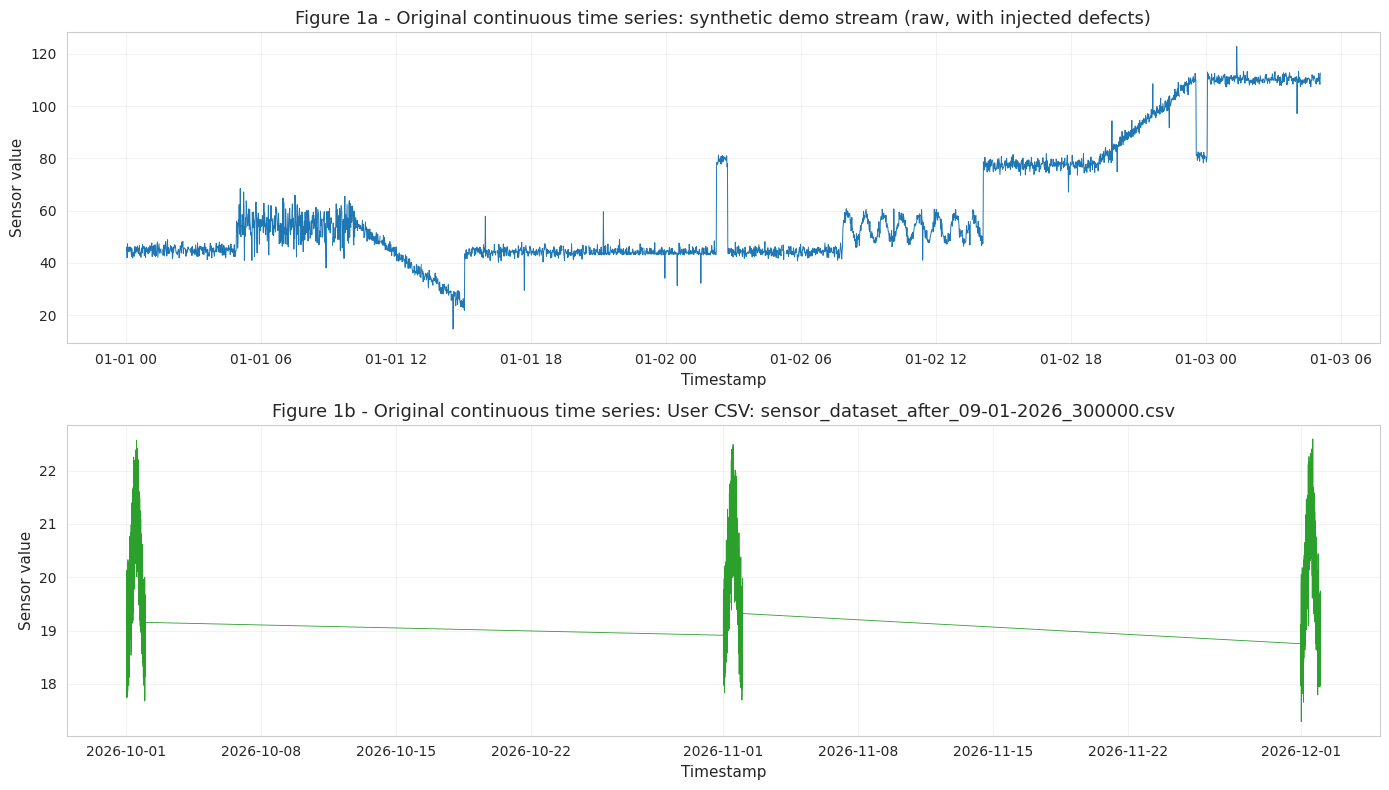

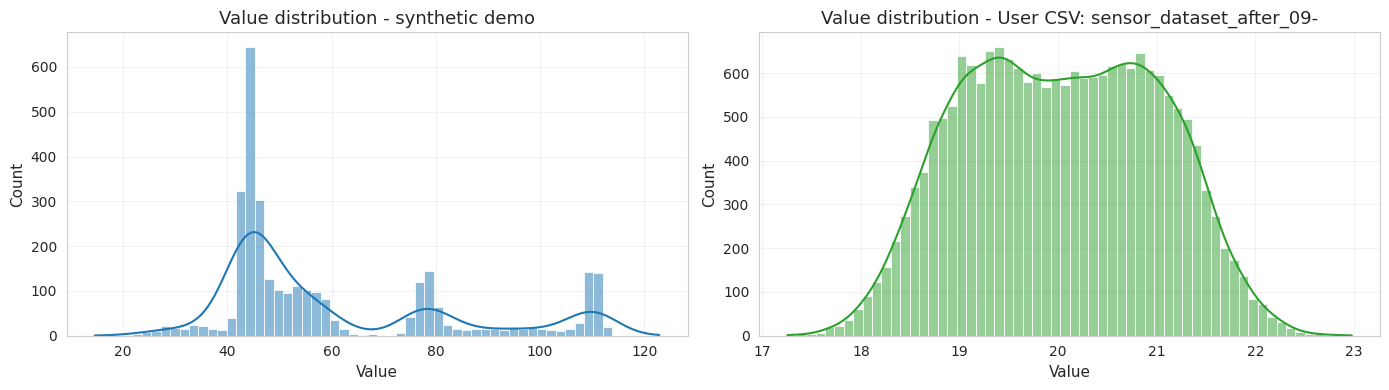

,count,mean,std,min,max
regime,,,,,
Decreasing Trend,288,39.56,9.15,14.62,57.27
High-Level,302,77.50,1.66,67.10,81.93
Increasing Trend,265,94.48,9.67,74.85,112.56
Noisy,316,54.51,5.00,38.02,68.47
Periodic,369,53.37,3.90,41.03,60.71
Skewed Distribution,346,44.10,1.71,31.31,59.54
Stable,1203,60.73,28.47,29.46,122.87
Sudden Drop,30,80.79,1.09,78.22,82.48
Sudden Spike,30,79.26,1.20,76.79,81.28


In [ ]:
DEMO = TEST_SEEDS[0]
df_demo_raw, truth_demo, regs_demo = RAW[DEMO]

def eda_summary(df, name):
    ts = pd.to_datetime(df["timestamp"], errors="coerce")
    return pd.Series({"rows": len(df), "missing values": int(df["value"].isna().sum()), "duplicate timestamps": int(ts.duplicated().sum()),
                      "out-of-order rows": int((ts.diff().dt.total_seconds() < 0).sum()), "min": df["value"].min(), "max": df["value"].max(),
                      "mean": df["value"].mean(), "std": df["value"].std(), "skewness": df["value"].skew()}, name=name)
display(pd.concat([eda_summary(df_demo_raw, "synthetic demo (raw)"), eda_summary(REAL_RAW, REAL_NAME)], axis=1).round(3))

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
d = df_demo_raw.assign(timestamp=pd.to_datetime(df_demo_raw.timestamp)).sort_values("timestamp")
axes[0].plot(d.timestamp, d.value, lw=0.7, color="tab:blue"); axes[0].set_title("Figure 1a - Original continuous time series: synthetic demo stream (raw, with injected defects)")
axes[0].set_xlabel("Timestamp"); axes[0].set_ylabel("Sensor value")
r = REAL_RAW.assign(timestamp=pd.to_datetime(REAL_RAW.timestamp))
axes[1].plot(r.timestamp, r.value, lw=0.6, color="tab:green"); axes[1].set_title(f"Figure 1b - Original continuous time series: {REAL_NAME}")
axes[1].set_xlabel("Timestamp"); axes[1].set_ylabel("Sensor value")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_demo_raw.value.dropna(), bins=60, kde=True, ax=axes[0], color="tab:blue"); axes[0].set_title("Value distribution - synthetic demo"); axes[0].set_xlabel("Value"); axes[0].set_ylabel("Count")
sns.histplot(REAL_RAW.value.dropna(), bins=60, kde=True, ax=axes[1], color="tab:green"); axes[1].set_title(f"Value distribution - {REAL_NAME[:34]}"); axes[1].set_xlabel("Value"); axes[1].set_ylabel("Count")
plt.tight_layout(); plt.show()

dd = df_demo_raw.drop_duplicates("timestamp").sort_values("timestamp").reset_index(drop=True)
dd["regime"] = [truth_demo.label[r] for r in regs_demo[:len(dd)]]
display(dd.groupby("regime").value.agg(["count", "mean", "std", "min", "max"]).round(2))

Lag-1 autocorrelation induced by the median filter on white noise: 0.55 (used later to correct test p-values for *excess* autocorrelation only)
Preprocessing report for the synthetic demo stream:


,preprocessing report
unparsable timestamps dropped,0.0
out-of-order rows (before sort),158.0
duplicate timestamps removed,12.0
missing values (incl. gaps),38.0
outliers replaced (Hampel),16.0
samples after preprocessing,3187.0
sampling step (s),60.0



Real/fallback dataset preprocessing report:


,preprocessing report
unparsable timestamps dropped,15680.0
out-of-order rows (before sort),0.0
duplicate timestamps removed,0.0
missing values (incl. gaps),84960.0
outliers replaced (Hampel),6.0
samples after preprocessing,89280.0
sampling step (s),60.0


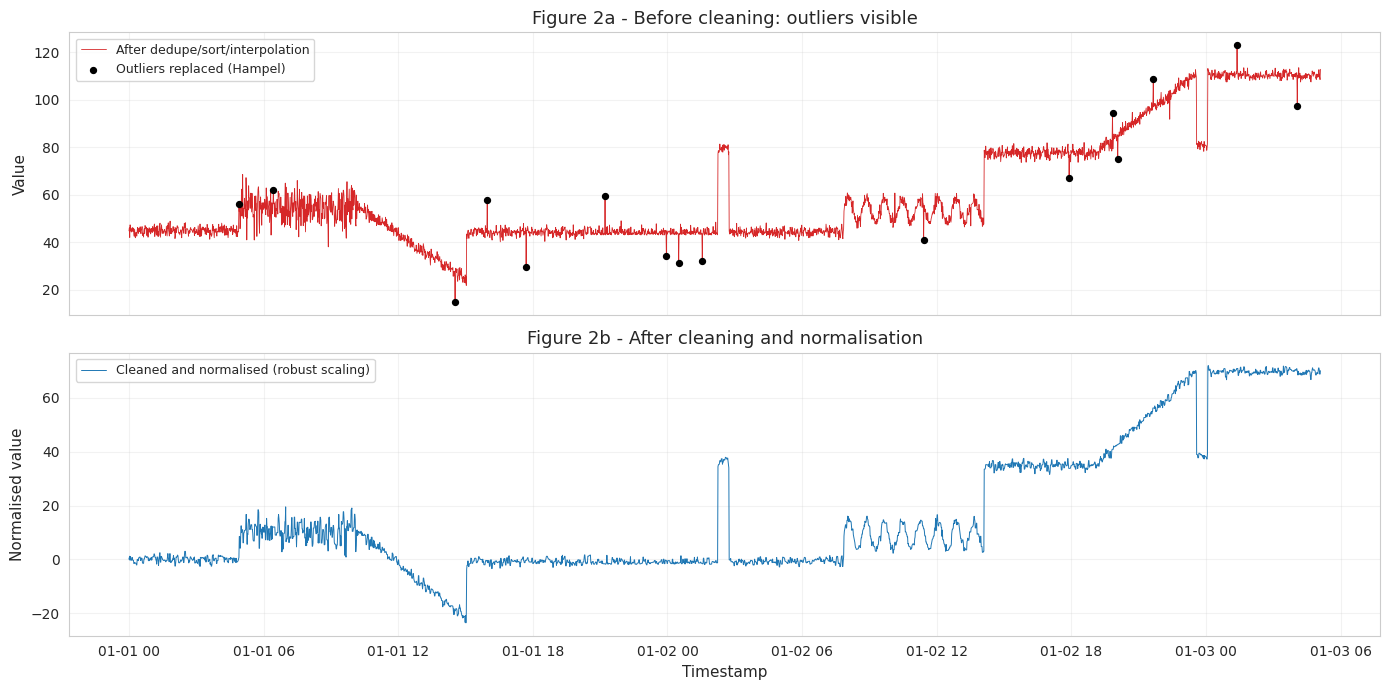

In [ ]:
def hampel(x, k=3, n_sigmas=5.0, noise_floor=0.0):
    pad = np.pad(x, k, mode="edge"); win = sliding_window_view(pad, 2 * k + 1)
    med = np.median(win, axis=1); mad = np.median(np.abs(win - med[:, None]), axis=1) * 1.4826
    thr = np.maximum(n_sigmas * mad, 3.0 * noise_floor)
    flag = np.abs(x - med) > thr
    return np.where(flag, med, x), flag

def robust_noise(x):
    d = np.diff(x); d = d[np.isfinite(d)]
    return 1.4826 * np.median(np.abs(d - np.median(d))) / np.sqrt(2) + 1e-12

def preprocess(df, warmup=200, report=True):
    rep = {}
    d = df.copy(); d["timestamp"] = pd.to_datetime(d["timestamp"], errors="coerce")
    rep["unparsable timestamps dropped"] = int(d.timestamp.isna().sum()); d = d.dropna(subset=["timestamp"])
    rep["out-of-order rows (before sort)"] = int((d.timestamp.diff().dt.total_seconds() < 0).sum()); d = d.sort_values("timestamp")
    rep["duplicate timestamps removed"] = int(d.timestamp.duplicated().sum()); d = d.drop_duplicates("timestamp", keep="first")
    step = d.timestamp.diff().dt.total_seconds().median()
    s = d.set_index("timestamp")["value"].resample(f"{int(step)}s").mean()
    rep["missing values (incl. gaps)"] = int(s.isna().sum())
    s = s.interpolate(method="time", limit=20, limit_direction="both").ffill().bfill()
    raw_filled = s.values.copy()
    noise = robust_noise(raw_filled[:warmup * 2])
    cleaned, flag = hampel(raw_filled, noise_floor=noise); rep["outliers replaced (Hampel)"] = int(flag.sum())
    smooth = pd.Series(cleaned).rolling(3, center=True, min_periods=1).median().values
    w = smooth[:warmup]; center = np.median(w); scale = (np.percentile(w, 75) - np.percentile(w, 25)) / 1.349
    if scale < 1e-9: scale = w.std() + 1e-9
    out = pd.DataFrame({"timestamp": s.index, "value_raw_filled": raw_filled, "value_clean": smooth, "value_norm": (smooth - center) / scale,
                        "outlier": flag})
    rep["samples after preprocessing"] = len(out); rep["sampling step (s)"] = step
    if report: display(pd.Series(rep, name="preprocessing report").to_frame())
    return out

class Stream:
    def __init__(self, df_raw, truth=None, regs=None, name=""):
        self.name = name; self.df = preprocess(df_raw, report=False); self.x = self.df.value_norm.values; self.ts = self.df.timestamp.values
        self.N = len(self.x); self.truth = truth; self.regs = regs
        self.true_cps = [] if truth is None else [int(v) for v in truth.start_idx.values[1:]]
        self.sigma0 = robust_noise(self.x[:150])

_w = np.random.default_rng(SEED).normal(0, 1, 100000); _m = np.median(sliding_window_view(_w, 3), axis=1)
RHO_BASE = float(np.corrcoef(_m[:-1], _m[1:])[0, 1])
print(f"Lag-1 autocorrelation induced by the median filter on white noise: {RHO_BASE:.2f} (used later to correct test p-values for *excess* autocorrelation only)")

print("Preprocessing report for the synthetic demo stream:")
STREAMS = {}
_ = preprocess(RAW[DEMO][0], report=True)
for sd in VAL_SEEDS + TEST_SEEDS:
    STREAMS[sd] = Stream(*RAW[sd][:3], name=f"synthetic-{sd}")
S = STREAMS[DEMO]
print("\nReal/fallback dataset preprocessing report:"); real_df_clean = preprocess(REAL_RAW)
assert S.N == len(RAW[DEMO][2]), "grid length must match ground truth length"

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(S.df.timestamp, S.df.value_raw_filled, lw=0.6, color="tab:red", label="After dedupe/sort/interpolation")
axes[0].scatter(S.df.timestamp[S.df.outlier], S.df.value_raw_filled[S.df.outlier], s=18, color="black", zorder=3, label="Outliers replaced (Hampel)")
axes[0].set_title("Figure 2a - Before cleaning: outliers visible"); axes[0].set_ylabel("Value"); axes[0].legend()
axes[1].plot(S.df.timestamp, S.x, lw=0.7, color="tab:blue", label="Cleaned and normalised (robust scaling)")
axes[1].set_title("Figure 2b - After cleaning and normalisation"); axes[1].set_xlabel("Timestamp"); axes[1].set_ylabel("Normalised value"); axes[1].legend()
plt.tight_layout(); plt.show()

Feature DataFrame shape: (632, 21)


,end_idx,timestamp,mean,var,std,min,max,median,range,slope,...,roc_mean,roc_abs,max_abs_diff,skew,kurtosis,iqr,q10,q90,entropy,true_regime
0,29,2024-01-01 00:29:00,-0.291,0.845,0.919,-2.01,1.209,-0.257,3.219,-0.017,...,0.011,0.491,2.041,-0.217,-0.982,1.735,-1.474,0.874,1.941,stable
1,34,2024-01-01 00:34:00,-0.341,0.763,0.873,-2.01,0.874,-0.284,2.884,0.028,...,0.025,0.359,2.041,-0.292,-0.996,1.648,-1.474,0.752,1.717,stable
2,39,2024-01-01 00:39:00,-0.534,0.801,0.895,-2.01,0.874,-0.395,2.884,0.026,...,-0.039,0.355,2.041,0.087,-1.285,1.674,-1.474,0.635,1.786,stable
3,44,2024-01-01 00:44:00,-0.278,1.000,1.000,-2.01,1.334,-0.171,3.344,0.057,...,0.085,0.398,2.041,-0.122,-1.276,1.915,-1.421,0.874,1.971,stable
4,49,2024-01-01 00:49:00,0.090,0.937,0.968,-2.01,1.334,0.381,3.344,0.051,...,0.103,0.405,2.041,-0.803,-0.488,1.280,-1.421,1.011,1.916,stable


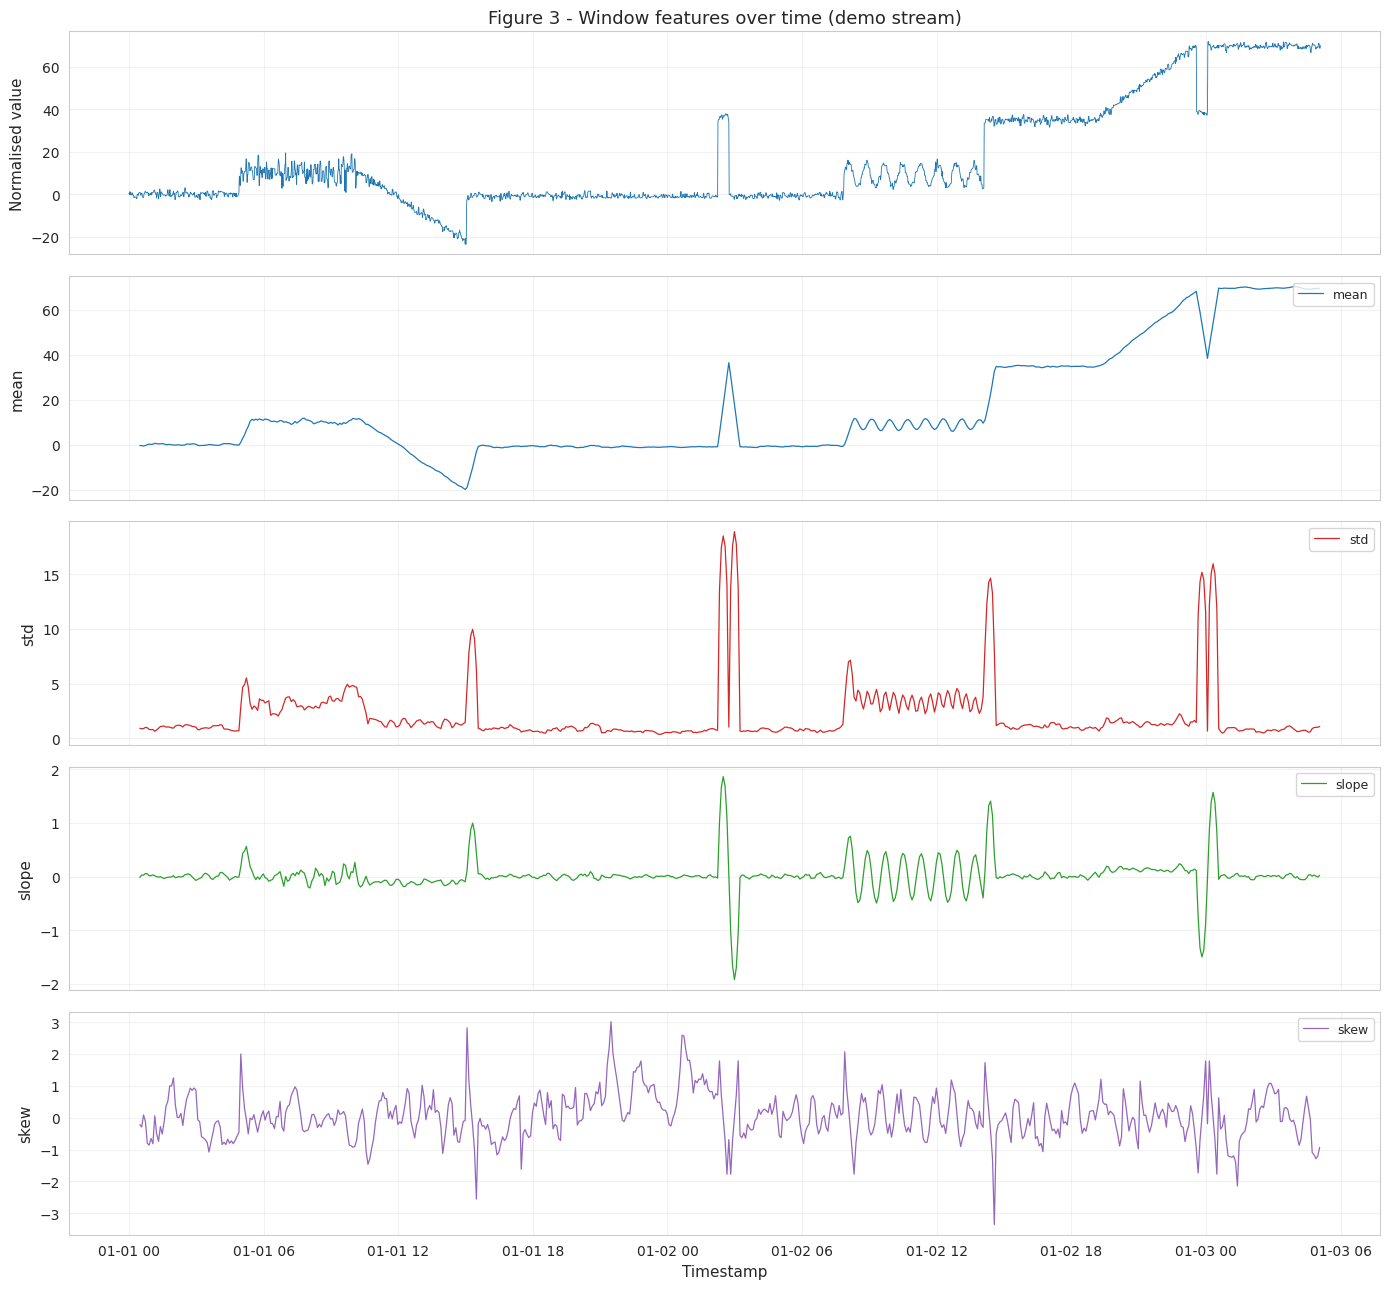

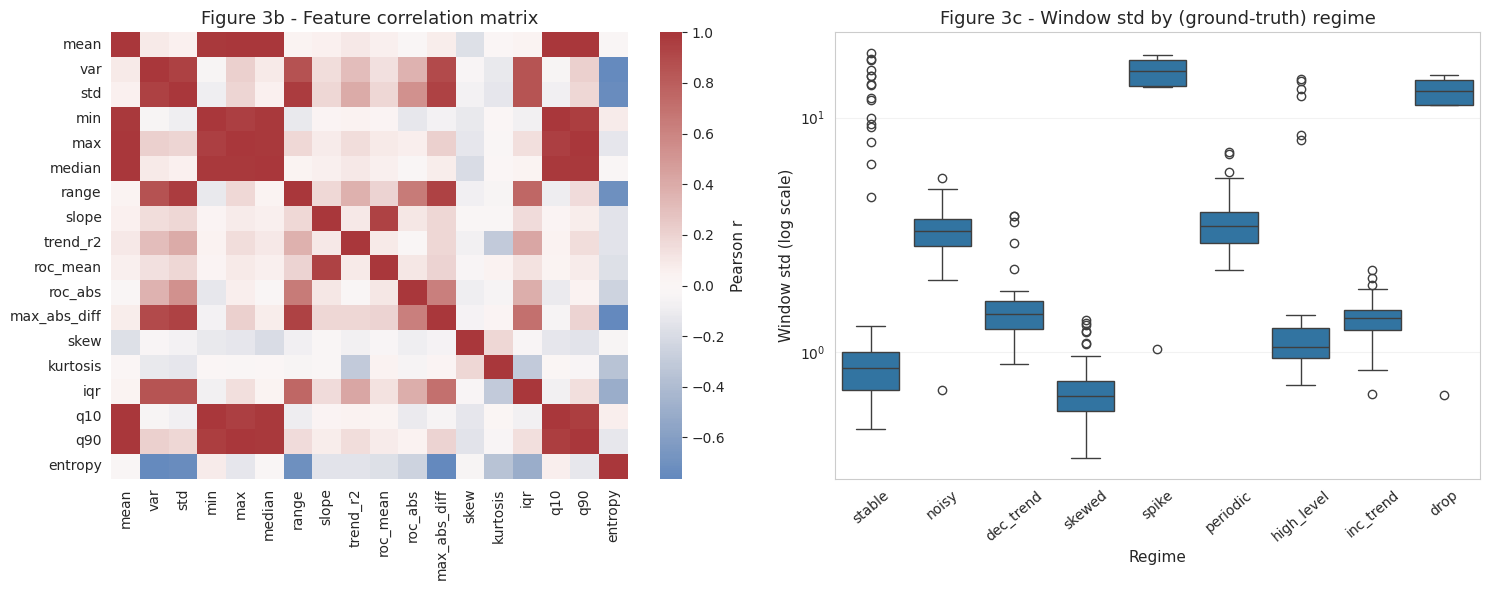

In [ ]:
FEATURE_COLS = ["mean", "var", "std", "min", "max", "median", "range", "slope", "trend_r2", "roc_mean", "roc_abs", "max_abs_diff",
                "skew", "kurtosis", "iqr", "q10", "q90", "entropy"]

def window_feature_matrix(W):
    n, w = W.shape; t = np.arange(w) - (w - 1) / 2; sxx = (t ** 2).sum()
    mean = W.mean(1); var = W.var(1); std = np.sqrt(var)
    slope = (W * t).sum(1) / sxx
    fit_var = slope ** 2 * sxx / w; r2 = np.where(var > 1e-12, np.clip(fit_var / np.maximum(var, 1e-12), 0, 1), 0.0)
    dif = np.diff(W, axis=1)
    q10, q25, q50, q75, q90 = np.percentile(W, [10, 25, 50, 75, 90], axis=1)
    ent = np.array([stats.entropy(np.histogram(r, bins=8)[0] + 1e-9) for r in W])
    return pd.DataFrame({"mean": mean, "var": var, "std": std, "min": W.min(1), "max": W.max(1), "median": q50, "range": W.max(1) - W.min(1),
                         "slope": slope, "trend_r2": r2, "roc_mean": dif.mean(1), "roc_abs": np.abs(dif).mean(1), "max_abs_diff": np.abs(dif).max(1),
                         "skew": stats.skew(W, axis=1), "kurtosis": stats.kurtosis(W, axis=1), "iqr": q75 - q25, "q10": q10, "q90": q90, "entropy": ent})

def extract_features(x, ts, w=30, step=5):
    W = sliding_window_view(x, w)[::step]; end = np.arange(w - 1, len(x), step)[:len(W)]
    F = window_feature_matrix(W); F.insert(0, "end_idx", end); F.insert(1, "timestamp", pd.to_datetime(ts[end]))
    return F

FEAT = extract_features(S.x, S.ts)
if S.regs is not None: FEAT["true_regime"] = [S.truth.regime[S.regs[i]] for i in FEAT.end_idx]
print("Feature DataFrame shape:", FEAT.shape); display(FEAT.head(5).round(3))

fig, axes = plt.subplots(5, 1, figsize=(14, 13), sharex=True)
axes[0].plot(S.ts, S.x, lw=0.6); axes[0].set_ylabel("Normalised value"); axes[0].set_title("Figure 3 - Window features over time (demo stream)")
for ax, col, c in zip(axes[1:], ["mean", "std", "slope", "skew"], ["tab:blue", "tab:red", "tab:green", "tab:purple"]):
    ax.plot(FEAT.timestamp, FEAT[col], color=c, lw=0.9, label=col); ax.set_ylabel(col); ax.legend(loc="upper right")
axes[-1].set_xlabel("Timestamp"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(FEAT[FEATURE_COLS].corr(), cmap="vlag", center=0, ax=axes[0], cbar_kws={"label": "Pearson r"}); axes[0].set_title("Figure 3b - Feature correlation matrix")
sns.boxplot(data=FEAT, x="true_regime", y="std", ax=axes[1]); axes[1].set_yscale("log"); axes[1].tick_params(axis="x", rotation=40)
axes[1].set_title("Figure 3c - Window std by (ground-truth) regime"); axes[1].set_xlabel("Regime"); axes[1].set_ylabel("Window std (log scale)")
plt.tight_layout(); plt.show()

,clusters,noise %,label flips along time,true change points,ARI vs true regime,NMI vs true regime,silhouette,Davies-Bouldin,Calinski-Harabasz
algorithm,,,,,,,,,
K-Means (k=2),2,0.0,20,11,0.097,0.203,0.470,1.322,224.3
DBSCAN (eps=1.88),2,4.1,28,11,0.006,0.061,0.677,0.394,107.7
"MiniBatch K-Means (k=2, incremental)",2,0.0,33,11,0.093,0.182,0.263,1.909,123.9


Observation: the number of label flips is much larger than the number of true change points -> clustering labels are not segments.


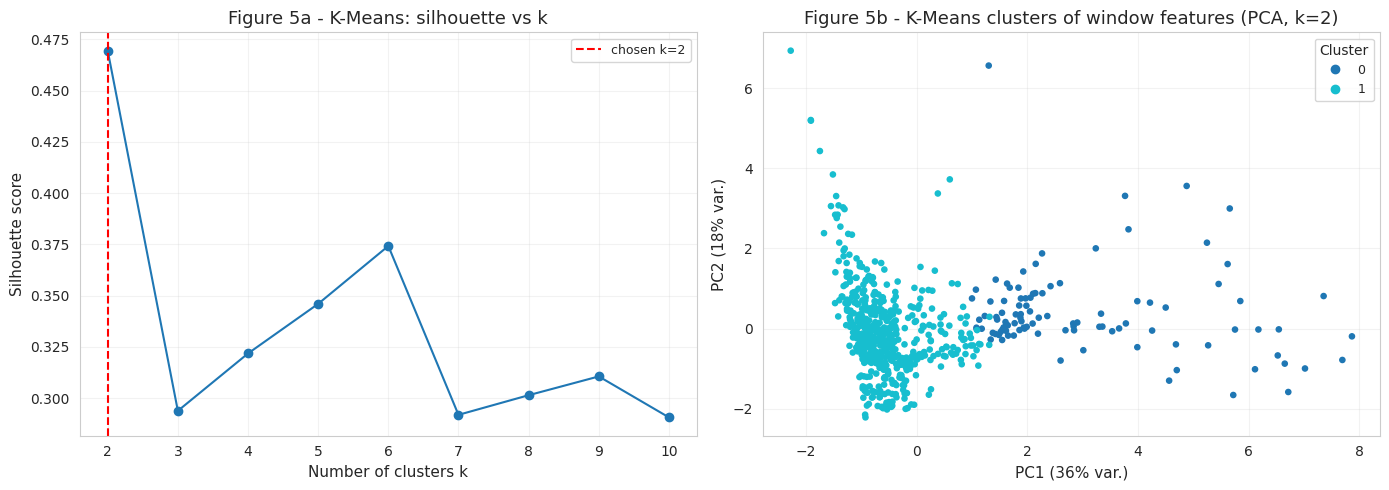

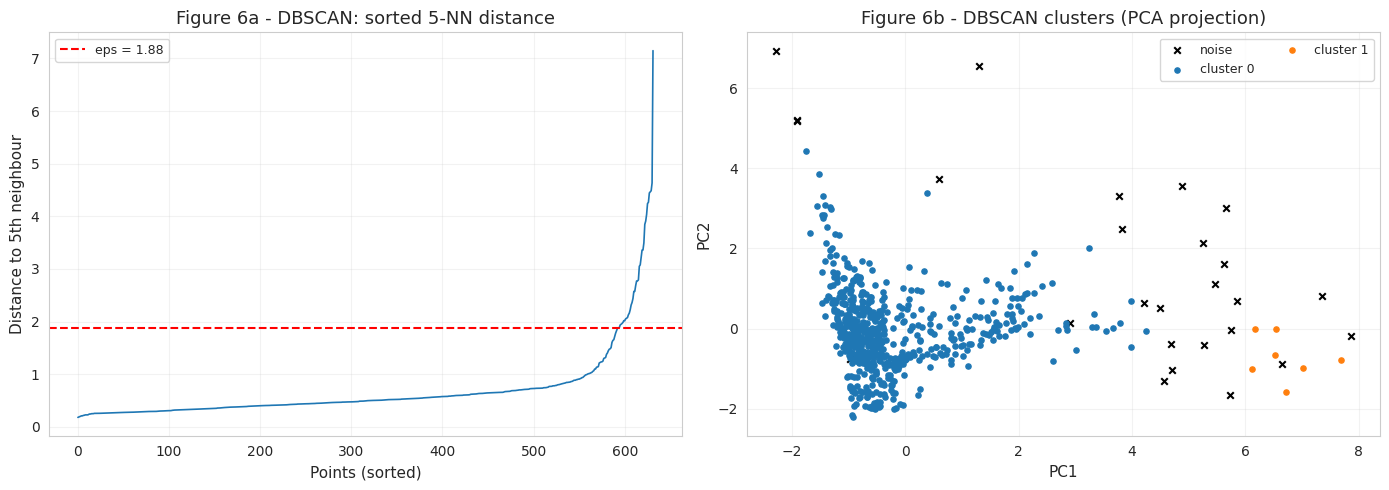

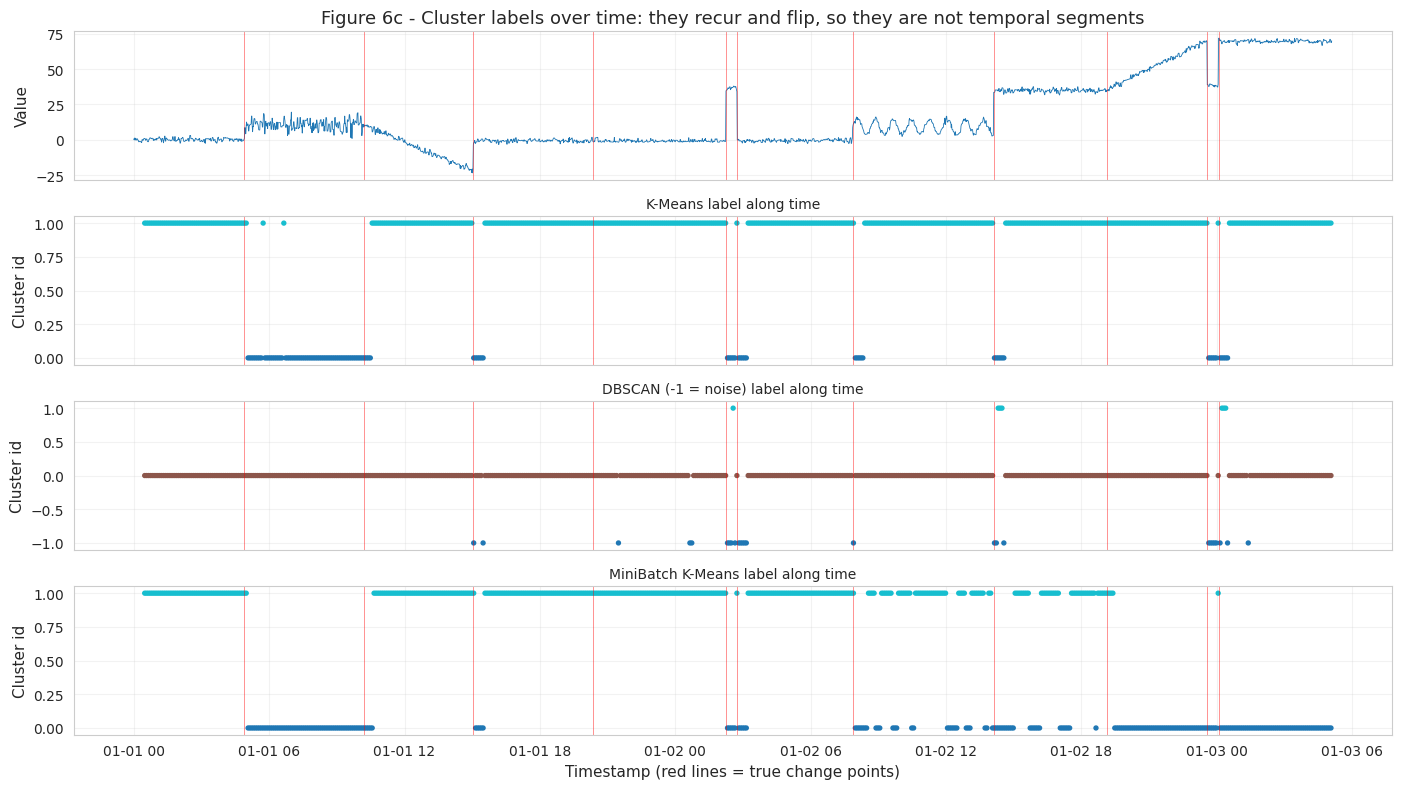

In [ ]:
CLUSTER_COLS = ["mean", "std", "slope", "skew", "roc_abs", "range", "kurtosis"]
Xc = StandardScaler().fit_transform(FEAT[CLUSTER_COLS].values)
true_win = FEAT.true_regime.values

sil_k = {k: silhouette_score(Xc, KMeans(k, n_init=10, random_state=SEED).fit_predict(Xc)) for k in range(2, 11)}
K_BEST = max(sil_k, key=sil_k.get); km = KMeans(K_BEST, n_init=10, random_state=SEED).fit(Xc); lab_km = km.labels_

mins = 5; kd = np.sort(NearestNeighbors(n_neighbors=mins).fit(Xc).kneighbors(Xc)[0][:, -1])
best = (-2, None, None)
for q in np.arange(0.5, 0.99, 0.04):
    e = float(np.quantile(kd, q)); l = DBSCAN(eps=e, min_samples=mins).fit_predict(Xc); m = l != -1
    if len(set(l[m])) >= 2 and m.sum() > 20:
        sc = silhouette_score(Xc[m], l[m])
        if sc > best[0]: best = (sc, e, q)
EPS = best[1] if best[1] else float(np.quantile(kd, 0.9)); lab_db = DBSCAN(eps=EPS, min_samples=mins).fit_predict(Xc)

sc_inc = StandardScaler(); mbk = MiniBatchKMeans(K_BEST, n_init=3, random_state=SEED, batch_size=64); chunk = 40
for a in range(0, len(FEAT), chunk):
    B = FEAT[CLUSTER_COLS].values[a:a + chunk]; sc_inc.partial_fit(B)
    if a == 0 and len(B) >= K_BEST: mbk.partial_fit(sc_inc.transform(B))
    elif a > 0: mbk.partial_fit(sc_inc.transform(B))
lab_mb = mbk.predict(sc_inc.transform(FEAT[CLUSTER_COLS].values))

def cluster_report(name, lab, X):
    m = lab != -1; nclu = len(set(lab[m]))
    row = {"algorithm": name, "clusters": nclu, "noise %": round(100 * (~m).mean(), 1), "label flips along time": int((np.diff(lab) != 0).sum()),
           "true change points": len(S.true_cps), "ARI vs true regime": round(adjusted_rand_score(true_win, lab), 3),
           "NMI vs true regime": round(normalized_mutual_info_score(true_win, lab), 3)}
    if nclu >= 2 and m.sum() > nclu:
        row.update({"silhouette": round(silhouette_score(X[m], lab[m]), 3), "Davies-Bouldin": round(davies_bouldin_score(X[m], lab[m]), 3),
                    "Calinski-Harabasz": round(calinski_harabasz_score(X[m], lab[m]), 1)})
    return row
CLUSTER_TABLE = pd.DataFrame([cluster_report(f"K-Means (k={K_BEST})", lab_km, Xc), cluster_report(f"DBSCAN (eps={EPS:.2f})", lab_db, Xc),
                              cluster_report(f"MiniBatch K-Means (k={K_BEST}, incremental)", lab_mb, Xc)]).set_index("algorithm")
display(CLUSTER_TABLE)
print("Observation: the number of label flips is much larger than the number of true change points -> clustering labels are not segments.")

pca = PCA(2, random_state=SEED).fit(Xc); P = pca.transform(Xc)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(list(sil_k), list(sil_k.values()), "o-"); ax[0].axvline(K_BEST, color="r", ls="--", label=f"chosen k={K_BEST}"); ax[0].legend()
ax[0].set_title("Figure 5a - K-Means: silhouette vs k"); ax[0].set_xlabel("Number of clusters k"); ax[0].set_ylabel("Silhouette score")
sc = ax[1].scatter(P[:, 0], P[:, 1], c=lab_km, cmap="tab10", s=14); ax[1].set_title(f"Figure 5b - K-Means clusters of window features (PCA, k={K_BEST})")
ax[1].set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.0f}% var.)"); ax[1].set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.0f}% var.)")
ax[1].legend(*sc.legend_elements(), title="Cluster", loc="best"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(kd, lw=1.2); ax[0].axhline(EPS, color="r", ls="--", label=f"eps = {EPS:.2f}"); ax[0].legend()
ax[0].set_title("Figure 6a - DBSCAN: sorted 5-NN distance"); ax[0].set_xlabel("Points (sorted)"); ax[0].set_ylabel("Distance to 5th neighbour")
for l in sorted(set(lab_db)):
    mk = lab_db == l; ax[1].scatter(P[mk, 0], P[mk, 1], s=14 if l != -1 else 22, c="k" if l == -1 else None, marker="x" if l == -1 else "o", label="noise" if l == -1 else f"cluster {l}")
ax[1].set_title("Figure 6b - DBSCAN clusters (PCA projection)"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].legend(ncol=2); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(4, 1, figsize=(14, 8), sharex=True)
for ax, lab, nm in zip(axes[1:], [lab_km, lab_db, lab_mb], ["K-Means", "DBSCAN (-1 = noise)", "MiniBatch K-Means"]):
    ax.scatter(FEAT.timestamp, lab, c=lab, cmap="tab10", s=8); ax.set_ylabel("Cluster id"); ax.set_title(f"{nm} label along time", fontsize=10)
axes[0].plot(S.ts, S.x, lw=0.6); axes[0].set_ylabel("Value"); axes[0].set_title("Figure 6c - Cluster labels over time: they recur and flip, so they are not temporal segments")
for c in S.true_cps:
    for ax in axes: ax.axvline(S.ts[c], color="r", lw=0.6, alpha=0.5)
axes[-1].set_xlabel("Timestamp (red lines = true change points)"); plt.tight_layout(); plt.show()

Detector backend: River (ADWIN, PageHinkley)
demo stream: 3187 samples, 11 true change points | alarms -> ADWIN: 8, Page-Hinkley: 34, sliding statistical test: 21 (0.71s)


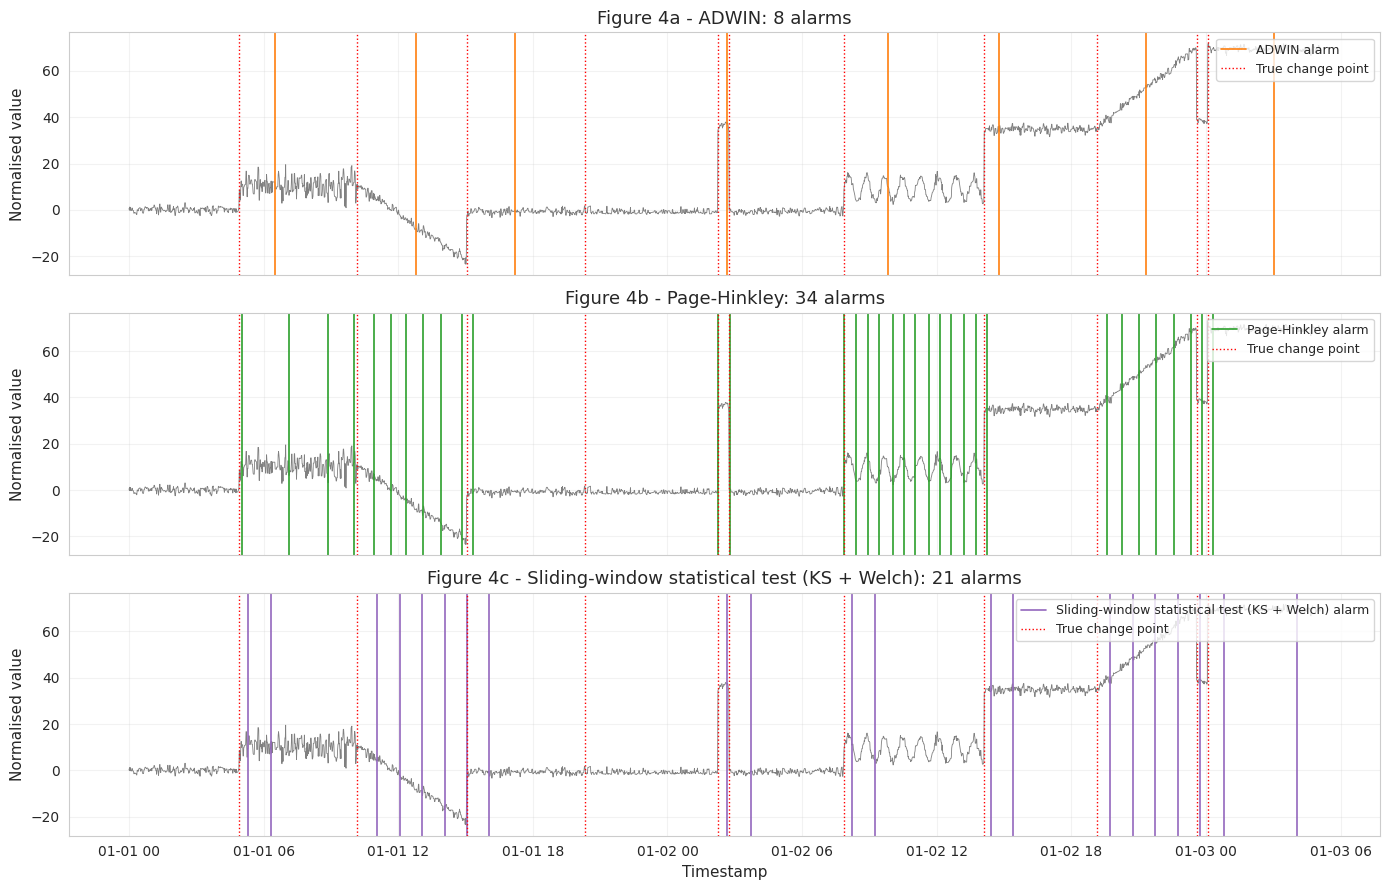

Detectors alone raise many alarms on trends / noisy / periodic phases (false boundaries) -> a confidence gate is needed.


In [ ]:

def _flag(det, ret=None):
    for attr in ("drift_detected", "change_detected"):
        if hasattr(det, attr): return bool(getattr(det, attr))
    return bool(ret[0] if isinstance(ret, tuple) else ret)

class RiverADWIN:
    def __init__(self, delta=0.002, clock=8):
        try: self.d = river_drift.ADWIN(delta=delta, clock=clock)
        except TypeError: self.d = river_drift.ADWIN(delta=delta)
    def update(self, x): return _flag(self.d, self.d.update(float(x)))
    @property
    def width(self): return int(getattr(self.d, "width", 0))

class RiverPH:
    def __init__(self, min_instances=30, delta=0.005, threshold=50.0, alpha=0.9999):
        try: self.d = river_drift.PageHinkley(min_instances=min_instances, delta=delta, threshold=threshold, alpha=alpha, mode="both")
        except TypeError: self.d = river_drift.PageHinkley(min_instances=min_instances, delta=delta, threshold=threshold, alpha=alpha)
    def update(self, x): return _flag(self.d, self.d.update(float(x)))

class FallbackADWIN:
    def __init__(self, delta=0.002, clock=8, max_len=600, min_len=8):
        self.delta, self.clock, self.max_len, self.min_len, self.buf, self.n = delta, clock, max_len, min_len, [], 0
    @property
    def width(self): return len(self.buf)
    def update(self, x):
        self.buf.append(float(x)); self.n += 1
        if len(self.buf) > self.max_len: self.buf.pop(0)
        if self.n % self.clock or len(self.buf) < 2 * self.min_len: return False
        a = np.asarray(self.buf); n = len(a); cs = np.cumsum(a)
        k = np.arange(self.min_len, n - self.min_len + 1); n0 = k.astype(float); n1 = n - n0
        m0 = cs[k - 1] / n0; m1 = (cs[-1] - cs[k - 1]) / n1
        m = 1.0 / (1.0 / n0 + 1.0 / n1); ln = np.log(2.0 / (self.delta / np.log(max(n, 3))))
        eps = np.sqrt(2.0 / m * max(a.var(), 1e-12) * ln) + 2.0 / (3.0 * m) * ln
        gap = np.abs(m0 - m1) - eps
        if (gap > 0).any():
            self.buf = self.buf[int(k[np.argmax(gap)]):]; return True
        return False

class FallbackPH:
    def __init__(self, min_instances=30, delta=0.005, threshold=50.0, alpha=0.9999):
        self.mi, self.delta, self.thr, self.alpha = min_instances, delta, threshold, alpha; self.reset()
    def reset(self): self.n, self.mean, self.up, self.dn = 0, 0.0, 0.0, 0.0
    def update(self, x):
        self.n += 1; self.mean += (x - self.mean) / self.n
        self.up = max(0.0, self.alpha * self.up + (x - self.mean - self.delta)); self.dn = max(0.0, self.alpha * self.dn + (self.mean - x - self.delta))
        if self.n >= self.mi and (self.up > self.thr or self.dn > self.thr): self.reset(); return True
        return False

def _selftest(factory):
    rs = np.random.default_rng(0); det = factory(); xs = np.r_[rs.normal(0.3, 0.05, 200), rs.normal(0.7, 0.05, 200)]
    fired = [i for i, v in enumerate(xs) if det.update(v)]
    return len(fired) > 0 and min(fired) >= 190

USE_RIVER = False
if RIVER_OK:
    try: USE_RIVER = _selftest(lambda: RiverADWIN()) and _selftest(lambda: RiverPH(30, 0.005, 5.0))
    except Exception as e: print("[info] River self-test failed, using fallback:", e)
assert _selftest(lambda: FallbackADWIN()) and _selftest(lambda: FallbackPH(30, 0.005, 5.0)), "fallback detectors failed self-test"
print("Detector backend:", "River (ADWIN, PageHinkley)" if USE_RIVER else "built-in fallback implementations (River unavailable)")

def make_adwin(delta=0.002, clock=8): return RiverADWIN(delta, clock) if USE_RIVER else FallbackADWIN(delta, clock)
def make_ph(min_instances=30, delta=0.005, threshold=50.0, alpha=0.9999):
    return RiverPH(min_instances, delta, threshold, alpha) if USE_RIVER else FallbackPH(min_instances, delta, threshold, alpha)

def detect_adwin(x, delta=0.002, clock=8):
    v = (x - x.min()) / (x.max() - x.min() + 1e-12)
    det = make_adwin(delta, clock); b, d = [], []
    for i, val in enumerate(v):
        if det.update(val): d.append(i); b.append(max(0, i - det.width))
    return dict(boundary=b, declared=d)

def detect_page_hinkley(x, delta=0.05, threshold=60.0):
    det = make_ph(30, delta, threshold, 0.9999); d = [i for i, val in enumerate(x) if det.update(val)]
    return dict(boundary=d[:], declared=d)

def detect_sliding_stats(x, w=60, stride=5, alpha=1e-6, refractory=60):
    b, d, last = [], [], -10 ** 9
    for t in range(2 * w, len(x) + 1, stride):
        a, c = x[t - 2 * w:t - w], x[t - w:t]
        p = min(stats.ks_2samp(a, c).pvalue, stats.ttest_ind(a, c, equal_var=False).pvalue)
        if p < alpha and t - last >= refractory: d.append(t - 1); b.append(t - 10); last = t
    return dict(boundary=b, declared=d)

t0 = time.perf_counter(); R_ad = detect_adwin(S.x); R_ph = detect_page_hinkley(S.x); R_ks = detect_sliding_stats(S.x)
print(f"demo stream: {S.N} samples, {len(S.true_cps)} true change points | alarms -> ADWIN: {len(R_ad['declared'])}, Page-Hinkley: {len(R_ph['declared'])}, sliding statistical test: {len(R_ks['declared'])} ({time.perf_counter()-t0:.2f}s)")

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, R, nm, col in zip(axes, [R_ad, R_ph, R_ks], ["ADWIN", "Page-Hinkley", "Sliding-window statistical test (KS + Welch)"], ["tab:orange", "tab:green", "tab:purple"]):
    ax.plot(S.ts, S.x, lw=0.6, color="gray"); ax.set_ylabel("Normalised value")
    for k, i in enumerate(R["declared"]): ax.axvline(S.ts[i], color=col, lw=1.2, label=f"{nm} alarm" if k == 0 else None)
    for k, c in enumerate(S.true_cps): ax.axvline(S.ts[c], color="red", lw=1, ls=":", label="True change point" if k == 0 else None)
    ax.set_title(f"Figure 4{'abc'[list(axes).index(ax)]} - {nm}: {len(R['declared'])} alarms"); ax.legend(loc="upper right")
axes[-1].set_xlabel("Timestamp"); plt.tight_layout(); plt.show()
print("Detectors alone raise many alarms on trends / noisy / periodic phases (false boundaries) -> a confidence gate is needed.")

In [ ]:
@dataclass
class SegConfig:

    stride: int = 4; w_test: int = 50; ref_max: int = 150; glr_L: int = 160
    min_fit: int = 8; min_ref: int = 10; min_post: int = 3; probation: int = 60; young_effect: float = 10.0; split_penalty: float = 20.0

    z_gate: float = 3.5; ref_hist: int = 200; prior_w: float = 10.0

    adwin_delta: float = 0.002; adwin_clock: int = 4; ph_delta: float = 0.1; ph_thr: float = 30.0; ph_min: int = 10; ph_alpha: float = 0.999

    alpha_open: float = 1e-4; alpha_sig: float = 1e-3; d_open: float = 0.4; s_max: float = 8.0; d0: float = 1.0; persist: int = 3
    weights: tuple = (0.25, 0.25, 0.25, 0.25)
    tau_low: float = 0.40; tau_med: float = 0.60; tau_high: float = 0.80
    patience: int = 6; max_open: int = 90

    use_confidence: bool = True; adapt: bool = True; thr_adapt: bool = True; thr_gain: float = 0.5; thr_cap: float = 0.15
    use_library: bool = True; lib_w: int = 30; seed: int = 42

def _acf1(a):
    a = np.asarray(a, float)
    if len(a) < 8 or a.std() < 1e-9: return 0.0
    return float(np.clip(np.corrcoef(a[:-1], a[1:])[0, 1], 0.0, 0.95))

def evidence_stats(post, pre, cfg, penalty=1.0):
    post, pre = np.asarray(post, float), np.asarray(pre, float); n1, n0 = len(post), len(pre)
    ps = [stats.ttest_ind(post, pre, equal_var=False).pvalue]
    sd0 = max(pre.std(), 0.5); d_mean = abs(post.mean() - pre.mean()) / sd0; d_scale = d_dist = 0.0
    if n1 >= 6:
        ps.append(stats.levene(post, pre, center="median").pvalue)
        ks = stats.ks_2samp(post, pre); ps.append(ks.pvalue)
        d_scale = abs(np.log2(max(post.std(), 1e-6) / max(pre.std(), 1e-6))); d_dist = 3.0 * ks.statistic
    if n1 >= 15:
        dsk = stats.skew(post) - stats.skew(pre); ps.append(2 * stats.norm.sf(abs(dsk) / np.sqrt(6.0 / n1 + 6.0 / n0))); d_dist = max(d_dist, abs(dsk) / 2.0)
    ps = [1.0 if not np.isfinite(p) else p for p in ps]

    rho = max(_acf1(pre), _acf1(post) if n1 >= 12 else 0.0); infl = max(1.0, ((1 + rho) / (1 - rho)) / ((1 + RHO_BASE) / (1 - RHO_BASE)))
    ps = [float(2 * stats.norm.sf(stats.norm.isf(min(p, 1.0) / 2) / np.sqrt(infl))) if p < 1.0 else 1.0 for p in ps]
    return dict(p_adj=float(min(1.0, penalty * len(ps) * min(ps))), d=float(max(d_mean, d_scale, d_dist)), d_mean=d_mean, d_scale=d_scale, d_dist=d_dist, rho=rho)

def glr_split(z, min_pre, min_post, var_floor=0.25):

    n = len(z)
    if n < min_pre + min_post: return None, 0.0
    c1, c2 = np.cumsum(z), np.cumsum(z * z); m = np.arange(min_pre, n - min_post + 1); n0 = m.astype(float); n1 = n - n0
    s0, q0 = c1[m - 1], c2[m - 1]; mu0, mu1 = s0 / n0, (c1[-1] - s0) / n1
    v0 = np.maximum(q0 / n0 - mu0 ** 2, var_floor); v1 = np.maximum((c2[-1] - q0) / n1 - mu1 ** 2, var_floor)
    mu = c1[-1] / n; v = max(c2[-1] / n - mu ** 2, var_floor)
    gain = n * np.log(v) - n0 * np.log(v0) - n1 * np.log(v1); j = int(np.argmax(gain))
    return int(m[j]), float(gain[j])

def confidence_score(e_det, p_adj, d, consec, cfg):
    e_sig = float(np.clip(-np.log10(max(p_adj, 1e-300)) / cfg.s_max, 0, 1)); e_eff = float(1 - np.exp(-d / cfg.d0)); e_per = float(min(1.0, consec / cfg.persist))
    w = cfg.weights; return float(w[0] * e_det + w[1] * e_sig + w[2] * e_eff + w[3] * e_per), (e_det, e_sig, e_eff, e_per)

def tier_of(score, cfg):
    return "Insignificant" if score < cfg.tau_low else "Low" if score < cfg.tau_med else "Medium" if score < cfg.tau_high else "High"

rs = np.random.default_rng(1); cfg0 = SegConfig(); rows = []
pre = rs.normal(0, 1, 120)
for nm, post, det_frac in [("no change", rs.normal(0, 1, 40), 0.0), ("tiny shift 0.5 sigma", rs.normal(0.5, 1, 40), 1/3), ("shift 1 sigma", rs.normal(1, 1, 40), 2/3),
                           ("shift 3 sigma", rs.normal(3, 1, 40), 1.0), ("noise x3", rs.normal(0, 3, 40), 2/3), ("skewed, same mean/std", (rs.exponential(1, 60) - 1), 1/3)]:
    ev = evidence_stats(post, pre, cfg0); sc, (a, b, c, d) = confidence_score(det_frac, ev["p_adj"], ev["d"], 3, cfg0)
    rows.append({"candidate": nm, "e_det": a, "p_adj": ev["p_adj"], "e_sig": b, "effect d": ev["d"], "e_eff": c, "e_per": d, "score C": sc, "tier": tier_of(sc, cfg0)})
display(pd.DataFrame(rows).set_index("candidate").round(4))
print("(controlled inputs with persistence = 3 checks; shows how components combine into C and tiers)")

,e_det,p_adj,e_sig,effect d,e_eff,e_per,score C,tier
candidate,,,,,,,,
no change,0.0000,0.3653,0.0547,0.6000,0.4512,1.0,0.3765,Insignificant
tiny shift 0.5 sigma,0.3333,0.0041,0.2985,1.0500,0.6501,1.0,0.5705,Low
shift 1 sigma,0.6667,0.0000,0.6372,1.2250,0.7062,1.0,0.7525,Medium
shift 3 sigma,1.0000,0.0000,1.0000,3.3665,0.9655,1.0,0.9914,High
noise x3,0.6667,0.0000,1.0000,1.5141,0.7800,1.0,0.8617,High
"skewed, same mean/std",0.3333,0.0000,0.9514,1.1258,0.6756,1.0,0.7401,Medium


(controlled inputs with persistence = 3 checks; shows how components combine into C and tiers)


In [ ]:
def window_feature_vector(w):
    t = np.arange(len(w)) - (len(w) - 1) / 2; dif = np.diff(w)
    return np.array([w.mean(), w.std(), (w * t).sum() / (t ** 2).sum(), stats.skew(w) if w.std() > 1e-9 else 0.0, np.abs(dif).mean(), w.max() - w.min()])

class SegmentModel:

    def __init__(self, sigma_prior, cfg): self.cfg, self.prior, self.a, self.b, self.sigma, self.fitted = cfg, sigma_prior, 0.0, 0.0, sigma_prior, False
    def predict(self, u): return self.a + self.b * u
    def fit(self, u, y, mature):
        n = len(y); um, ym = u.mean(), y.mean(); uc = u - um; sxx = (uc ** 2).sum(); b = 0.0
        if n >= 12 and sxx > 0:
            bb = (uc * (y - ym)).sum() / sxx; res = y - ym - bb * uc; s2 = (res ** 2).sum() / max(n - 2, 1)
            if abs(bb / np.sqrt(s2 / sxx + 1e-18)) > (4.0 if mature else 3.0): b = bb
        self.b = b; self.a = ym - b * um; rms = np.sqrt(np.mean((y - self.predict(u)) ** 2))
        self.sigma = max(np.sqrt((n * rms ** 2 + self.cfg.prior_w * self.prior ** 2) / (n + self.cfg.prior_w)), 1e-6); self.fitted = True

class PatternLibrary:
    def __init__(self, k0=4, k_max=10, init_n=30, batch=8, nov_persist=6, seed=42):
        self.k0, self.k_max, self.init_n, self.batch, self.nov_persist, self.seed = k0, k_max, init_n, batch, nov_persist, seed
        self.scaler, self.mbk, self.buf, self.pending, self.run, self.mu, self.var = StandardScaler(), None, [], [], [], 0.0, 1.0
    @property
    def k(self): return 0 if self.mbk is None else len(self.mbk.cluster_centers_)
    def update(self, f):
        f = np.asarray(f, float); self.scaler.partial_fit(f[None])
        if self.mbk is None:
            self.buf.append(f)
            if len(self.buf) >= self.init_n:
                Sb = self.scaler.transform(np.array(self.buf)); self.mbk = MiniBatchKMeans(self.k0, n_init=3, random_state=self.seed, batch_size=64).fit(Sb)
                d = self.mbk.transform(Sb).min(1); self.mu, self.var = float(d.mean()), float(d.var() + 1e-6)
            return -1, np.nan, False
        s = self.scaler.transform(f[None]); dist = self.mbk.transform(s)[0]; cid = int(dist.argmin()); d = float(dist[cid]); new = False
        if d > self.mu + 4 * np.sqrt(self.var) and d > 1.5:
            self.run.append(s[0])
            if len(self.run) >= self.nov_persist and self.k < self.k_max:       # persistent novelty -> learn a new pattern
                C = np.vstack([self.mbk.cluster_centers_, np.mean(self.run, axis=0)]); self.run = []
                self.mbk = MiniBatchKMeans(len(C), init=C, n_init=1, random_state=self.seed, batch_size=64); self.mbk.partial_fit(C); new = True
        else:
            self.run = []; self.mu = 0.98 * self.mu + 0.02 * d; self.var = 0.98 * self.var + 0.02 * (d - self.mu) ** 2
            self.pending.append(s[0])
            if len(self.pending) >= self.batch: self.mbk.partial_fit(np.array(self.pending)); self.pending = []
        return cid, d, new

class AdaptiveSegmenter:
    def __init__(self, cfg, sigma0):
        self.cfg, self.sigma0 = cfg, sigma0; self.x, self.z, self.acc = [], [], []; self.seg_start = 0
        self.model = SegmentModel(sigma0, cfg); self.cand = None; self.noise_ev = 0.0
        self.boundaries, self.declared, self.events = [], [], []
        self.lib = PatternLibrary(seed=cfg.seed) if cfg.use_library else None
        self.tr = {k: [] for k in ("pred", "sigma", "tau", "score")}; self.lib_tr = []; self.cur_score = np.nan; self._new_detectors()

    def _new_detectors(self):
        c = self.cfg; self.adw_m = make_adwin(c.adwin_delta, c.adwin_clock); self.adw_s = make_adwin(c.adwin_delta, c.adwin_clock)
        self.ph = make_ph(c.ph_min, c.ph_delta, c.ph_thr, c.ph_alpha)
    def _feed(self, z):
        zc = max(-8.0, min(8.0, z)); out = []
        if self.adw_m.update(0.5 + zc / 16.0): out.append("ADWIN-mean")
        if self.adw_s.update(min(abs(z), 8.0) / 8.0): out.append("ADWIN-scale")
        if self.ph.update(zc): out.append("PageHinkley")
        return out

    def _refit(self, i):
        c = self.cfg; lo = max(self.seg_start, i - c.ref_hist + 1); mask = np.asarray(self.acc[lo:i + 1])
        idx = np.arange(lo, i + 1)[mask]
        if len(idx) < c.min_fit: return
        y = np.asarray(self.x[lo:i + 1])[mask]; self.model.fit(idx.astype(float), y, mature=(i - self.seg_start + 1) >= 80)
    def _replay(self):
        i = len(self.x) - 1; s = self.seg_start; idx = np.arange(s, i + 1)
        self.z[s:i + 1] = list((np.asarray(self.x[s:i + 1]) - self.model.predict(idx.astype(float))) / self.model.sigma)
        self._new_detectors()
        for zz in self.z[s:i + 1]: self._feed(zz)
    def _tau(self, young):
        c = self.cfg
        if not c.use_confidence: return 0.0
        if young: return c.tau_high
        return c.tau_med + (min(c.thr_cap, c.thr_gain * max(0.0, self.noise_ev - 0.25)) if c.thr_adapt else 0.0)

    def _open(self, i, fired): self.cand = dict(open_idx=i, det=set(fired), checks=0, consec=0, nosig=0, best=0.0, onset=None)
    def _scan(self, i):
        c = self.cfg; zs = np.asarray(self.z[self.seg_start:i + 1])
        if len(zs) < c.w_test + c.min_ref: return False
        post, pre = zs[-c.w_test:], zs[max(0, len(zs) - c.w_test - c.ref_max):len(zs) - c.w_test]
        ev = evidence_stats(post, pre, c); return ev["p_adj"] < c.alpha_open and ev["d"] >= c.d_open
    def _evaluate(self, i):
        c, cd = self.cfg, self.cand; cd["checks"] += 1; zs = np.asarray(self.z[self.seg_start:i + 1]); L = min(len(zs), c.glr_L)
        m, _ = glr_split(zs[-L:], c.min_ref, c.min_post)
        if m is None: return
        off = len(zs) - L + m; onset = self.seg_start + off; post, pre = zs[off:], zs[max(0, off - c.ref_max):off]
        if len(pre) < c.min_ref or len(post) < c.min_post: return
        ev = evidence_stats(post, pre, c, penalty=c.split_penalty)
        if ev["p_adj"] < c.alpha_sig: cd["consec"] += 1; cd["nosig"] = 0
        else: cd["consec"] = 0; cd["nosig"] += 1
        score, comps = confidence_score(len(cd["det"]) / 3.0, ev["p_adj"], ev["d"], cd["consec"], c)
        cd.update(onset=onset, ev=ev, comps=comps, best=max(cd["best"], score)); self.cur_score = score
        young = (onset - self.seg_start) < c.probation
        if score >= self._tau(young) and (not young or not c.use_confidence or ev["d"] >= c.young_effect): self._confirm(i, onset, score, comps, ev, young)
        elif cd["nosig"] >= c.patience or (i - cd["open_idx"]) > c.max_open: self._discard(i)
    def _record(self, i, status, score, onset, comps=None, ev=None, young=False):
        self.events.append(dict(det_idx=i, onset=int(onset), score=float(score), tier=tier_of(score, self.cfg), status=status, young=young,
                                e_det=None if comps is None else comps[0], e_sig=None if comps is None else comps[1], e_eff=None if comps is None else comps[2],
                                e_per=None if comps is None else comps[3], p_adj=None if ev is None else ev["p_adj"], effect=None if ev is None else ev["d"]))
    def _confirm(self, i, onset, score, comps, ev, young):
        c = self.cfg; self._record(i, "confirmed", score, onset, comps, ev, young); self.boundaries.append(int(onset)); self.declared.append(int(i))
        self.seg_start = int(onset); self.model = SegmentModel(self.model.sigma, c); self.cand = None; self.cur_score = np.nan
        self.z[onset:] = [np.nan] * (i + 1 - onset); self.acc[onset:] = [True] * (i + 1 - onset); self._new_detectors()
        if i + 1 - onset >= c.min_fit: self._refit(i); self._replay()
    def _discard(self, i, status="suppressed"):
        c, cd = self.cfg, self.cand; self._record(i, status, cd["best"], cd["onset"] if cd["onset"] is not None else cd["open_idx"], None, cd.get("ev"))
        lo = max(self.seg_start, cd["open_idx"] - c.w_test // 2); self.acc[lo:i + 1] = [True] * (i + 1 - lo)     # absorb benign fluctuation
        self.noise_ev = 0.7 * self.noise_ev + 0.3 * cd["best"]; self.cand = None; self.cur_score = np.nan

    def update(self, x):
        c = self.cfg; i = len(self.x); self.x.append(float(x)); n_seg = i - self.seg_start + 1
        if self.model.fitted: pred = self.model.predict(i); z = (x - pred) / self.model.sigma
        else: pred, z = np.nan, np.nan
        self.z.append(z); self.acc.append(bool(n_seg < c.probation or not np.isfinite(z) or abs(z) < c.z_gate))
        if self.model.fitted:
            fired = self._feed(z)
            if fired:
                if self.cand is None and n_seg >= c.min_fit: self._open(i, fired)
                elif self.cand is not None: self.cand["det"].update(fired)
        elif n_seg >= c.min_fit: self._refit(i); self._replay()
        if self.model.fitted and i % c.stride == 0: self._stride_step(i)
        self.tr["pred"].append(pred); self.tr["sigma"].append(self.model.sigma); self.tr["tau"].append(self._tau(False)); self.tr["score"].append(self.cur_score)
    def _stride_step(self, i):
        c = self.cfg
        if self.cand is None and self._scan(i): self._open(i, [])
        if self.cand is not None: self._evaluate(i)
        if self.cand is None and c.adapt: self._refit(i)
        self.noise_ev *= 0.995
        if self.lib is not None and i >= c.lib_w:
            cid, d, new = self.lib.update(window_feature_vector(np.asarray(self.x[i - c.lib_w + 1:i + 1]))); self.lib_tr.append((i, cid, d, self.lib.k, new))
    def finish(self):
        if self.cand is not None: self._discard(len(self.x) - 1, "unresolved")

def run_segmenter(x, cfg, sigma0):
    seg = AdaptiveSegmenter(cfg, sigma0); t0 = time.perf_counter()
    for v in x: seg.update(v)
    seg.finish(); return seg, time.perf_counter() - t0

CFG = SegConfig(); SEG, T_RUN = run_segmenter(S.x, CFG, S.sigma0)
print(f"Streamed {S.N} samples in {T_RUN:.2f}s ({1e6*T_RUN/S.N:.0f} microseconds/sample) | confirmed boundaries: {len(SEG.boundaries)} | candidate events: {len(SEG.events)}")
print("Pattern library: prototypes =", SEG.lib.k, "| novel patterns learned =", sum(1 for t in SEG.lib_tr if t[4]))

Streamed 3187 samples in 3.73s (1169 microseconds/sample) | confirmed boundaries: 15 | candidate events: 22
Pattern library: prototypes = 10 | novel patterns learned = 6


In [ ]:
def segment_stats(x, s, e):
    seg = x[s:e]; n = len(seg); u = np.arange(n, dtype=float)
    if n >= 3:
        b, a = np.polyfit(u, seg, 1); res = seg - (a + b * u); tot = ((seg - seg.mean()) ** 2).sum(); r2 = 1 - (res ** 2).sum() / tot if tot > 0 else 0.0
    else: b, a, res, r2 = 0.0, seg.mean(), seg - seg.mean(), 0.0
    ac = 0.0
    if n >= 40:
        r = res - res.mean(); full = np.correlate(r, r, "full")[n - 1:]; full = full / (full[0] + 1e-12); lo, hi = 5, min(n // 2, 150); ac = float(full[lo:hi].max()) if hi > lo else 0.0
    return dict(n=n, mean=float(seg.mean()), median=float(np.median(seg)), slope=float(b), change=float(b * n), r2=float(r2), sigma_r=float(res.std()),
                skew=float(stats.skew(seg)) if n >= 8 and seg.std() > 1e-9 else 0.0, acf=ac)

def label_segments(x, bounds, spike_max=60):
    edges = [0] + list(bounds) + [len(x)]; st = [segment_stats(x, edges[j], edges[j + 1]) for j in range(len(edges) - 1)]
    longs = [s["sigma_r"] for s in st if s["n"] >= spike_max]; sig_typ = max(float(np.median(longs)) if longs else float(np.median([s["sigma_r"] for s in st])), 1e-6)
    q1, med, q3 = np.percentile(x, [25, 50, 75]); iqr = max(q3 - q1, 1e-9); labels = []
    for j, s in enumerate(st):
        a, b = edges[j], edges[j + 1]
        if s["n"] < spike_max:
            nb = []
            if a > 0: nb.append(np.median(x[max(0, a - 10):a]))
            if b < len(x): nb.append(np.median(x[b:b + 10]))
            if nb and s["median"] > max(nb) + 6 * sig_typ: labels.append("Sudden Spike")
            elif nb and s["median"] < min(nb) - 6 * sig_typ: labels.append("Sudden Drop")
            else: labels.append("Unknown Pattern")
        elif abs(s["change"]) > 6 * sig_typ and s["r2"] > 0.6: labels.append("Increasing Trend" if s["change"] > 0 else "Decreasing Trend")
        elif s["acf"] > 0.5 and s["sigma_r"] > 2.5 * sig_typ: labels.append("Periodic")
        elif s["sigma_r"] > 2.5 * sig_typ: labels.append("Noisy")
        elif abs(s["skew"]) > 0.8 and s["n"] >= 100: labels.append("Skewed Distribution")
        elif s["median"] > med + 0.75 * iqr: labels.append("High-Level")
        elif s["sigma_r"] <= 2.0 * sig_typ: labels.append("Stable")
        else: labels.append("Unknown Pattern")
    return labels, st, edges

def build_segment_table(S, seg, calibrator=None):
    labels, st, edges = label_segments(S.x, seg.boundaries); ev_by_onset = {e["onset"]: e for e in seg.events if e["status"] == "confirmed"}
    lib_ids = np.array([t[1] for t in seg.lib_tr]) if seg.lib_tr else np.array([]); lib_pos = np.array([t[0] for t in seg.lib_tr]) if seg.lib_tr else np.array([])
    step = pd.Timedelta(np.median(np.diff(S.ts)).astype("timedelta64[s]").astype(int), unit="s"); rows = []
    for j in range(len(edges) - 1):
        a, b = edges[j], edges[j + 1]; e = ev_by_onset.get(a)
        if e is None: conf, cal, tier = "initial", np.nan, "-"
        else:
            cal = float(calibrator(e["score"])) if calibrator is not None else np.nan; conf = f"{e['score']:.2f} ({e['tier']})"; tier = e["tier"]
        sel = lib_ids[(lib_pos >= a + CFG.lib_w) & (lib_pos < b)] if len(lib_ids) else np.array([]); sel = sel[sel >= 0]
        rows.append({"Segment ID": j + 1, "Start Time": pd.Timestamp(S.ts[a]), "End Time": pd.Timestamp(S.ts[b - 1]), "Duration": pd.Timestamp(S.ts[b - 1]) - pd.Timestamp(S.ts[a]) + step,
                     "Pattern": labels[j], "Confidence": conf, "Calibrated P(change)": cal, "Samples": b - a, "Library cluster": int(np.bincount(sel).argmax()) if len(sel) else -1})
    return pd.DataFrame(rows)

TABLE = build_segment_table(S, SEG)
pd.set_option("display.width", 220, "display.max_columns", 20)
display(TABLE.drop(columns=["Calibrated P(change)"]))
print("Candidate events that did NOT create a segment (suppressed / low confidence):", sum(e["status"] != "confirmed" for e in SEG.events))
display(pd.DataFrame(SEG.events).round(3).head(25))

,Segment ID,Start Time,End Time,Duration,Pattern,Confidence,Samples,Library cluster
0,1,2024-01-01 00:00:00,2024-01-01 04:54:00,0 days 04:55:00,Stable,initial,295,0
1,2,2024-01-01 04:55:00,2024-01-01 10:07:00,0 days 05:13:00,Noisy,0.65 (Medium),313,0
2,3,2024-01-01 10:08:00,2024-01-01 11:57:00,0 days 01:50:00,Decreasing Trend,0.66 (Medium),110,1
3,4,2024-01-01 11:58:00,2024-01-01 15:02:00,0 days 03:05:00,Decreasing Trend,0.67 (Medium),185,1
4,5,2024-01-01 15:03:00,2024-01-01 19:26:00,0 days 04:24:00,Stable,0.65 (Medium),264,3
5,6,2024-01-01 19:27:00,2024-01-02 02:14:00,0 days 06:48:00,Skewed Distribution,0.61 (Medium),408,3
6,7,2024-01-02 02:15:00,2024-01-02 02:44:00,0 days 00:30:00,Sudden Spike,0.67 (Medium),30,-1
7,8,2024-01-02 02:45:00,2024-01-02 07:51:00,0 days 05:07:00,Stable,0.83 (High),307,3
8,9,2024-01-02 07:52:00,2024-01-02 14:06:00,0 days 06:15:00,Periodic,0.67 (Medium),375,3
9,10,2024-01-02 14:07:00,2024-01-02 19:15:00,0 days 05:09:00,High-Level,0.75 (Medium),309,3


Candidate events that did NOT create a segment (suppressed / low confidence): 7


,det_idx,onset,score,tier,status,young,e_det,e_sig,e_eff,e_per,p_adj,effect
0,72,40,0.307,Insignificant,suppressed,False,NaN,NaN,NaN,NaN,0.090,1.438
1,300,295,0.654,Medium,confirmed,False,0.333,0.951,1.000,0.333,0.000,7.925
2,660,608,0.665,Medium,confirmed,False,0.333,0.551,0.775,1.000,0.000,1.490
3,764,718,0.669,Medium,confirmed,False,0.000,0.883,0.792,1.000,0.000,1.571
4,908,903,0.646,Medium,confirmed,False,0.333,0.916,1.000,0.333,0.000,17.318
5,1088,1000,0.319,Insignificant,suppressed,False,NaN,NaN,NaN,NaN,0.004,1.032
6,1200,1167,0.612,Medium,confirmed,False,0.000,0.661,0.787,1.000,0.000,1.546
7,1316,1235,0.538,Low,suppressed,False,NaN,NaN,NaN,NaN,0.070,1.034
8,1580,1575,0.667,Medium,confirmed,False,0.333,1.000,1.000,0.333,0.000,55.280
9,1616,1605,0.833,High,confirmed,True,0.333,1.000,1.000,1.000,0.000,20.450


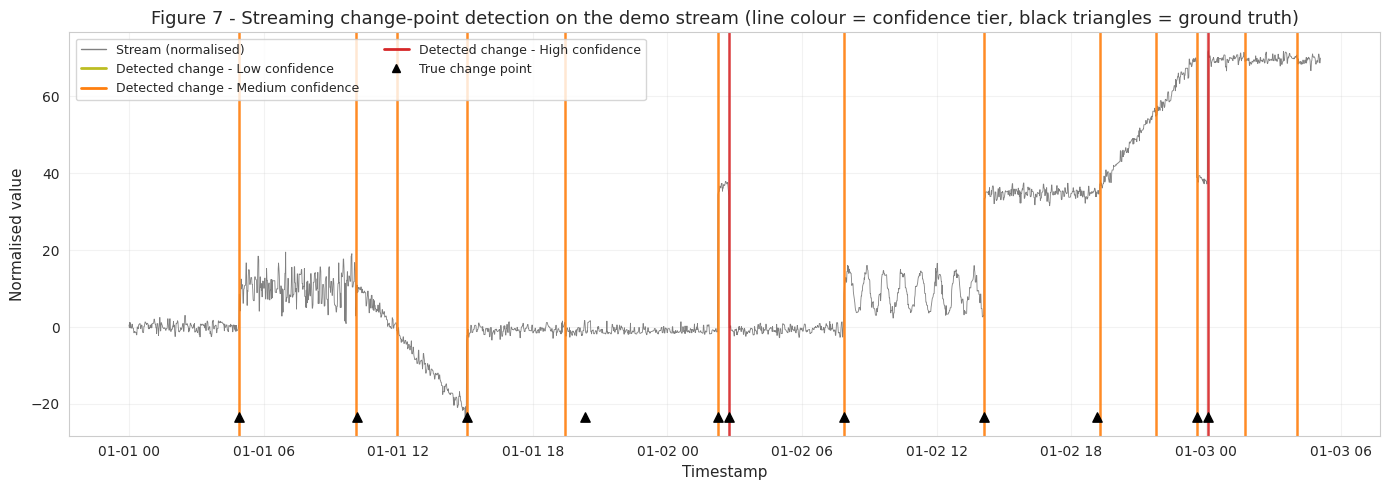

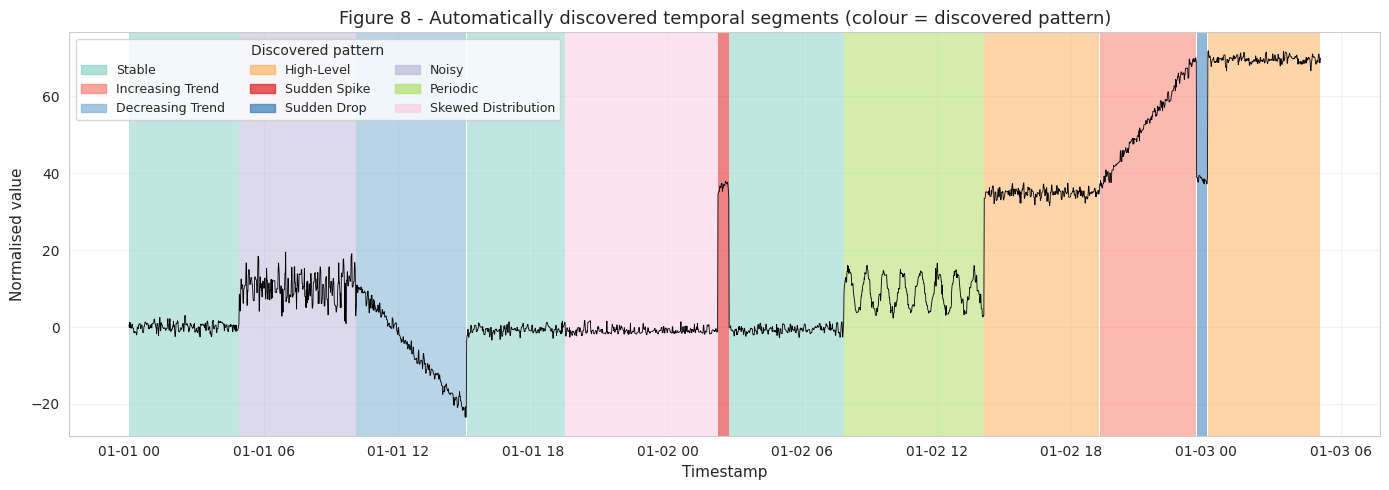

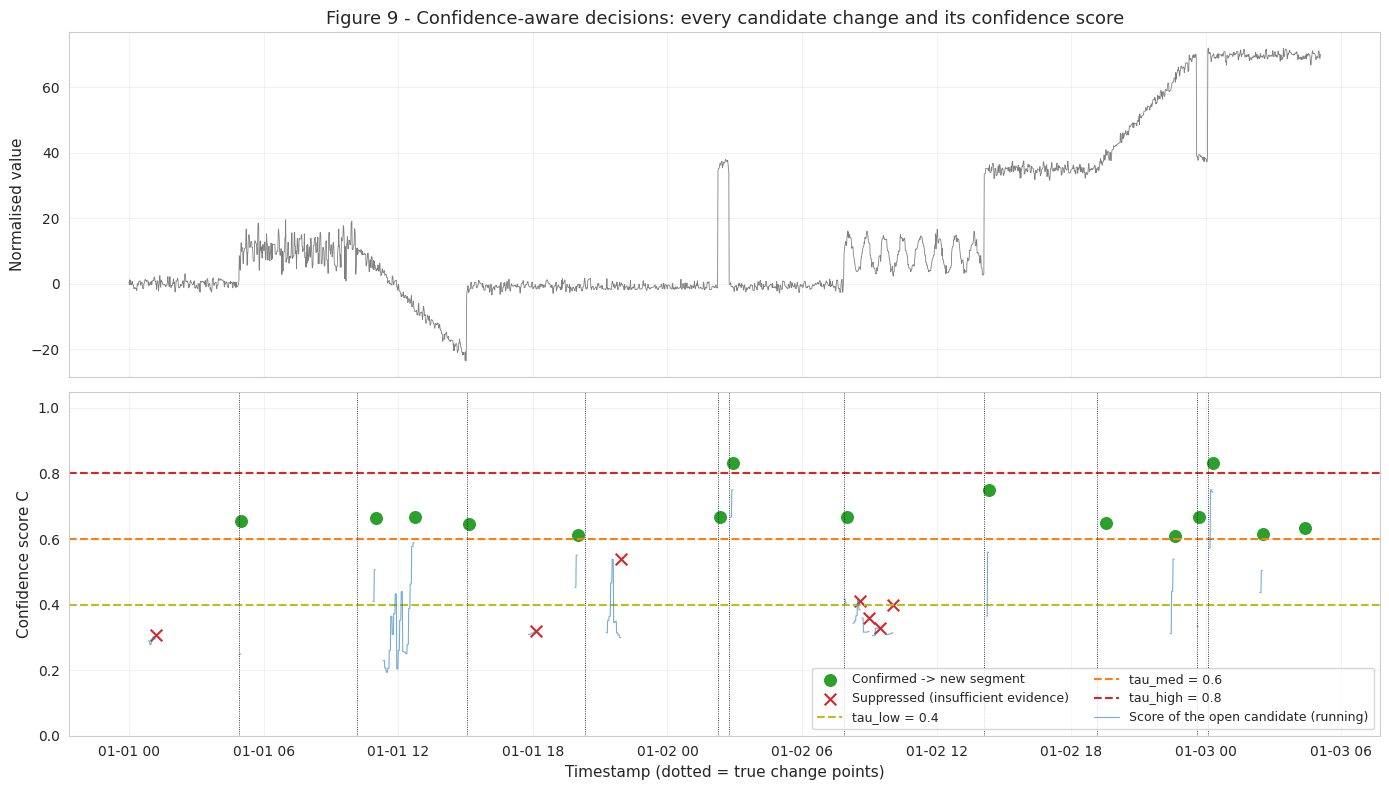

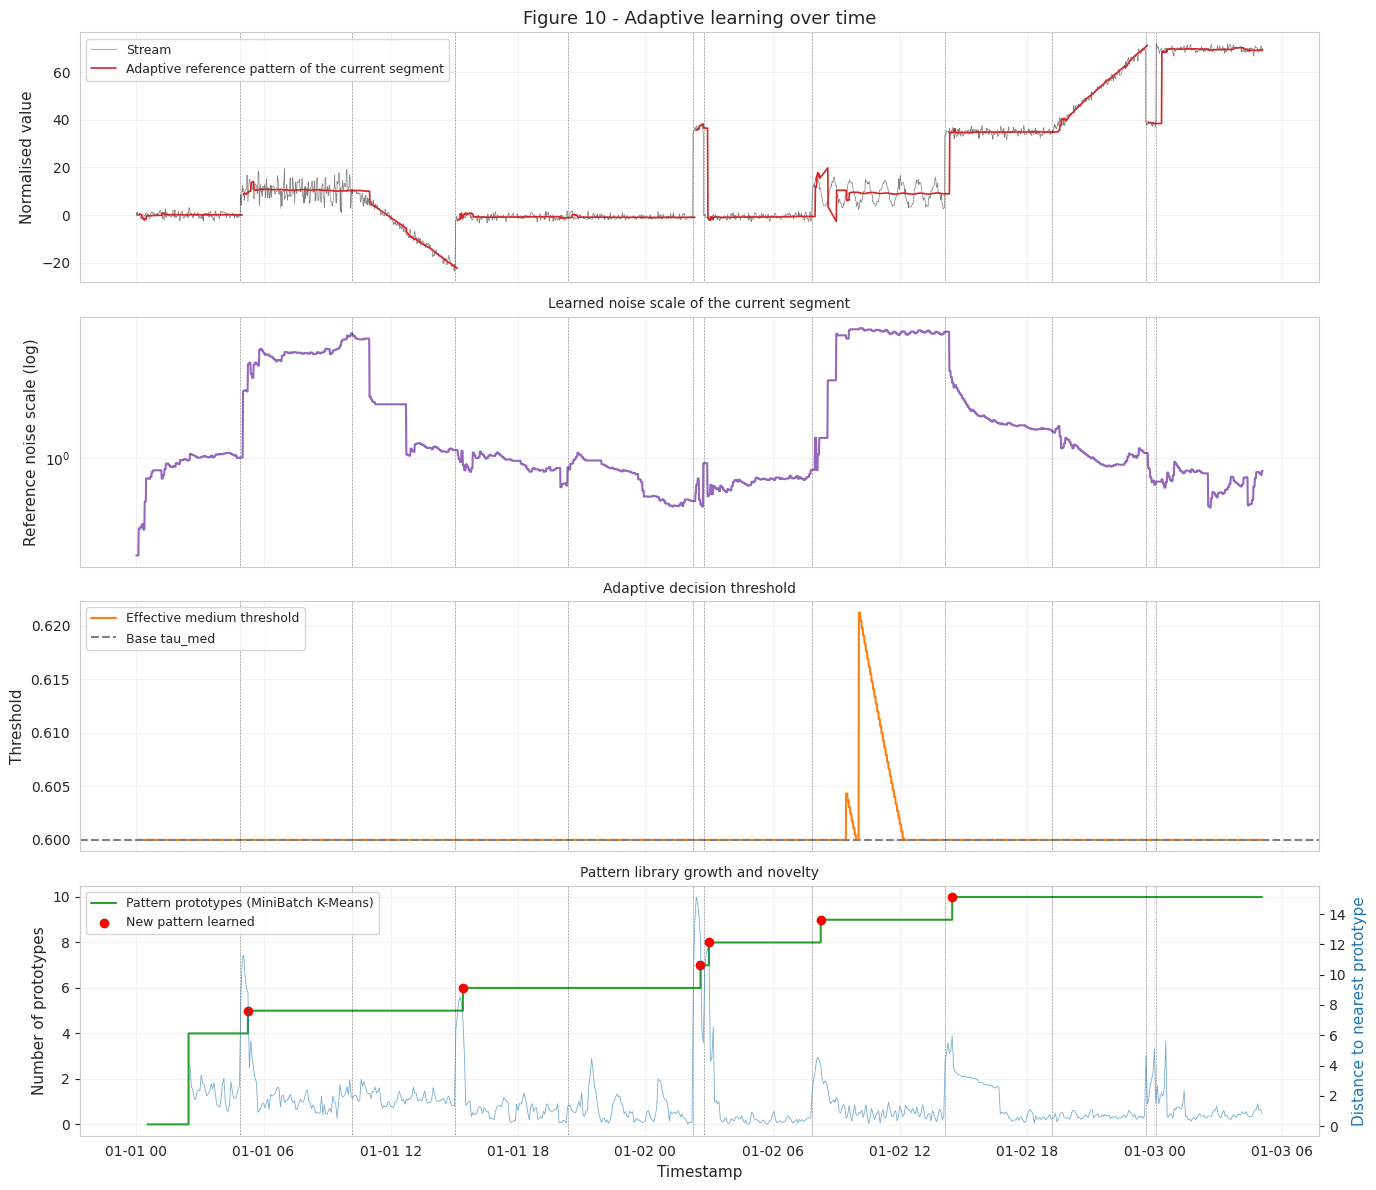

Dominant period detected in the real/fallback stream (samples): 22320 -> detector windows scaled to one cycle
User CSV: sensor_dataset_after_09-01-2026_300000.csv: 89280 samples, streamed in 131.7s, 3 confirmed boundaries (no ground truth available for this stream)


,Segment ID,Start Time,End Time,Duration,Pattern,Confidence,Samples,Library cluster
0,1,2026-10-01 00:00:00,2026-10-18 01:40:00,17 days 01:41:00,Skewed Distribution,initial,24581,1
1,2,2026-10-18 01:41:00,2026-10-31 23:39:00,13 days 21:59:00,Stable,0.63 (Medium),20039,1
2,3,2026-10-31 23:40:00,2026-11-01 00:03:00,0 days 00:24:00,Unknown Pattern,0.83 (High),24,-1
3,4,2026-11-01 00:04:00,2026-12-01 23:59:00,30 days 23:56:00,Skewed Distribution,0.83 (High),44636,7


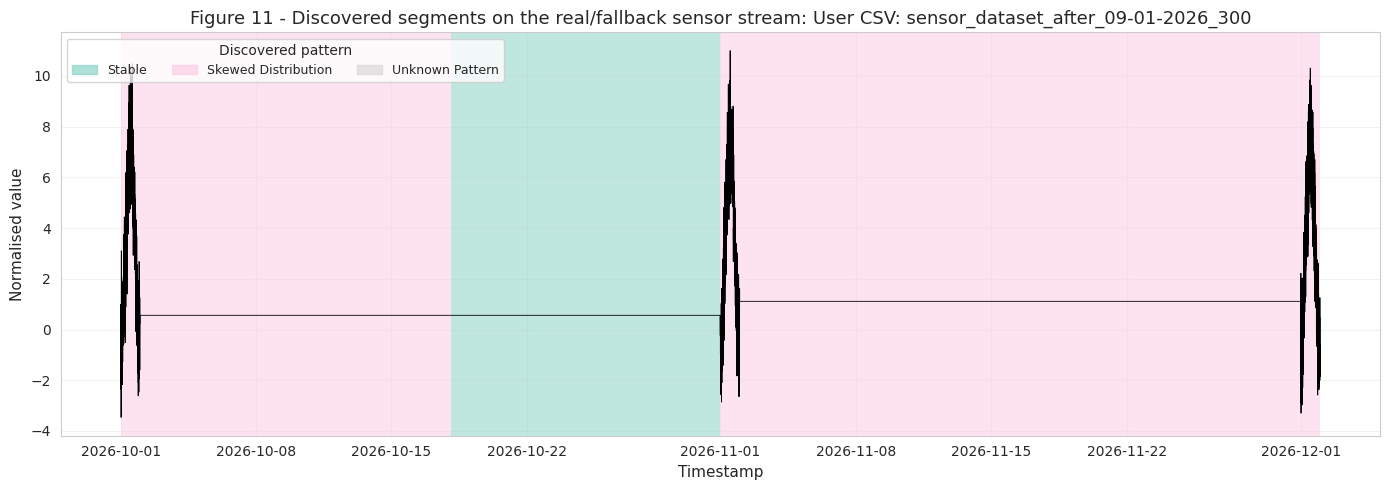

In [ ]:
PAT_COLORS = {"Stable": "#8dd3c7", "Increasing Trend": "#fb8072", "Decreasing Trend": "#80b1d3", "High-Level": "#fdb462", "Sudden Spike": "#e41a1c",
              "Sudden Drop": "#377eb8", "Noisy": "#bebada", "Periodic": "#b3de69", "Skewed Distribution": "#fccde5", "Unknown Pattern": "#d9d9d9"}
TIER_COLORS = {"Low": "tab:olive", "Medium": "tab:orange", "High": "tab:red"}
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def plot_detections(S, seg, title, truth=True):
    fig, ax = plt.subplots(figsize=(14, 5)); ax.plot(S.ts, S.x, lw=0.6, color="gray", label="Stream (normalised)")
    for e in seg.events:
        if e["status"] == "confirmed": ax.axvline(S.ts[e["onset"]], color=TIER_COLORS.get(e["tier"], "k"), lw=1.8, alpha=0.9)
    h = [Line2D([0], [0], color="gray", lw=1, label="Stream (normalised)")] + [Line2D([0], [0], color=c, lw=2, label=f"Detected change - {t} confidence") for t, c in TIER_COLORS.items()]
    if truth and S.true_cps:
        ax.scatter(S.ts[S.true_cps], [S.x.min()] * len(S.true_cps), marker="^", color="k", s=45, zorder=5); h.append(Line2D([0], [0], marker="^", color="k", ls="", label="True change point"))
    ax.set_title(title); ax.set_xlabel("Timestamp"); ax.set_ylabel("Normalised value"); ax.legend(handles=h, loc="upper left", ncol=2); plt.tight_layout(); plt.show()

def plot_segments(S, table, title):
    fig, ax = plt.subplots(figsize=(14, 5)); ax.plot(S.ts, S.x, lw=0.6, color="k")
    for _, r in table.iterrows(): ax.axvspan(r["Start Time"], r["End Time"], color=PAT_COLORS[r["Pattern"]], alpha=0.55, lw=0)
    used = [p for p in PAT_COLORS if p in set(table.Pattern)]
    ax.legend(handles=[Patch(color=PAT_COLORS[p], alpha=0.7, label=p) for p in used], loc="upper left", ncol=3, title="Discovered pattern")
    ax.set_title(title); ax.set_xlabel("Timestamp"); ax.set_ylabel("Normalised value"); plt.tight_layout(); plt.show()

plot_detections(S, SEG, "Figure 7 - Streaming change-point detection on the demo stream (line colour = confidence tier, black triangles = ground truth)")
plot_segments(S, TABLE, "Figure 8 - Automatically discovered temporal segments (colour = discovered pattern)")

ev = pd.DataFrame(SEG.events); fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(S.ts, S.x, lw=0.6, color="gray"); axes[0].set_ylabel("Normalised value"); axes[0].set_title("Figure 9 - Confidence-aware decisions: every candidate change and its confidence score")
for st, mk, col, nm in [("confirmed", "o", "tab:green", "Confirmed -> new segment"), ("suppressed", "x", "tab:red", "Suppressed (insufficient evidence)")]:
    q = ev[ev.status == st]
    if len(q): axes[1].scatter(S.ts[q.det_idx.values], q.score, marker=mk, s=70, color=col, label=nm)
for thr, nm, c in [(CFG.tau_low, "tau_low", "tab:olive"), (CFG.tau_med, "tau_med", "tab:orange"), (CFG.tau_high, "tau_high", "tab:red")]: axes[1].axhline(thr, ls="--", color=c, label=f"{nm} = {thr}")
axes[1].plot(S.ts, np.array(SEG.tr["score"], float), color="tab:blue", lw=0.8, alpha=0.6, label="Score of the open candidate (running)")
for c in S.true_cps: axes[1].axvline(S.ts[c], color="k", lw=0.6, ls=":")
axes[1].set_ylim(0, 1.05); axes[1].set_xlabel("Timestamp (dotted = true change points)"); axes[1].set_ylabel("Confidence score C"); axes[1].legend(loc="lower right", ncol=2); plt.tight_layout(); plt.show()

lt = np.array(SEG.lib_tr, float); fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
axes[0].plot(S.ts, S.x, lw=0.5, color="gray", label="Stream"); axes[0].plot(S.ts, SEG.tr["pred"], lw=1.2, color="tab:red", label="Adaptive reference pattern of the current segment")
axes[0].set_ylabel("Normalised value"); axes[0].set_title("Figure 10 - Adaptive learning over time"); axes[0].legend(loc="upper left")
axes[1].semilogy(S.ts, SEG.tr["sigma"], color="tab:purple"); axes[1].set_ylabel("Reference noise scale (log)"); axes[1].set_title("Learned noise scale of the current segment", fontsize=10)
axes[2].plot(S.ts, SEG.tr["tau"], color="tab:orange", label="Effective medium threshold"); axes[2].axhline(CFG.tau_med, ls="--", color="gray", label="Base tau_med")
axes[2].set_ylabel("Threshold"); axes[2].legend(loc="upper left"); axes[2].set_title("Adaptive decision threshold", fontsize=10)
axes[3].step(S.ts[lt[:, 0].astype(int)], lt[:, 3], where="post", color="tab:green", label="Pattern prototypes (MiniBatch K-Means)")
nv = lt[lt[:, 4] == 1]; axes[3].scatter(S.ts[nv[:, 0].astype(int)], nv[:, 3], color="red", zorder=5, label="New pattern learned")
ax2 = axes[3].twinx(); ax2.plot(S.ts[lt[:, 0].astype(int)], lt[:, 2], color="tab:blue", lw=0.6, alpha=0.6); ax2.set_ylabel("Distance to nearest prototype", color="tab:blue"); ax2.grid(False)
axes[3].set_ylabel("Number of prototypes"); axes[3].set_xlabel("Timestamp"); axes[3].legend(loc="upper left"); axes[3].set_title("Pattern library growth and novelty", fontsize=10)
for c in S.true_cps:
    for ax in axes: ax.axvline(S.ts[c], color="k", lw=0.4, ls=":")
plt.tight_layout(); plt.show()

SR = Stream(REAL_RAW, name=REAL_NAME)
def dominant_period(x, min_p=20):

    xc = x - np.polyval(np.polyfit(np.arange(len(x)), x, 1), np.arange(len(x))); P = np.abs(np.fft.rfft(xc)) ** 2; k = int(np.argmax(P[3:]) + 3); p = len(x) / k
    return int(round(p)) if min_p <= p <= len(x) / 4 and P[k] > 20 * np.median(P[3:]) else None
PER = dominant_period(SR.x)
if PER: CFG_REAL = replace(CFG, w_test=PER, ref_max=2 * PER, glr_L=2 * PER, ref_hist=3 * PER, probation=PER, adwin_clock=8, lib_w=min(PER, 100))   # windows span about one cycle
else:   CFG_REAL = replace(CFG, adwin_clock=8)
print("Dominant period detected in the real/fallback stream (samples):", PER, "-> detector windows scaled to one cycle" if PER else "")
SEG_R, T_R = run_segmenter(SR.x, CFG_REAL, SR.sigma0); TABLE_R = build_segment_table(SR, SEG_R)
print(f"{REAL_NAME}: {SR.N} samples, streamed in {T_R:.1f}s, {len(SEG_R.boundaries)} confirmed boundaries (no ground truth available for this stream)")
display(TABLE_R.drop(columns=["Calibrated P(change)"]).head(20))
plot_segments(SR, TABLE_R, f"Figure 11 - Discovered segments on the real/fallback sensor stream: {REAL_NAME[:45]}")

,Precision,Recall,F1,FAR_per_1000,Delay
tau_med,,,,,
0.5,0.629,0.667,0.646,1.339,13.185
0.6,0.694,0.667,0.677,1.025,14.804
0.7,0.678,0.576,0.622,0.925,15.038


Selected tau_med = 0.6 (highest mean validation F1; ties -> larger threshold)
Platt calibrator fitted on 162 validation candidate events (90 true / 72 false) and saved with joblib.


,score C,calibrated P(true change)
0,0.30,0.413
1,0.45,0.528
2,0.60,0.640
3,0.70,0.708
4,0.80,0.768
5,0.90,0.818
6,1.00,0.860


Test streams: [11, 12, 13, 14, 15] | true change points per stream: [11, 11, 11, 11, 11]


,Precision,Recall,F1,FAR_per_1000,Delay,LocError,ARI,NMI,Boundaries,Time_s,us_per_sample
method,,,,,,,,,,,
Fixed window (W=200),0.234,0.327,0.273,3.706,20.767,23.267,0.582,0.792,15.4,0.000,0.001
K-Means based,0.778,0.636,0.695,0.631,22.789,13.394,0.581,0.805,9.0,0.334,105.190
ADWIN based,0.402,0.255,0.311,1.321,25.083,189.467,0.463,0.704,7.0,0.003,1.099
Sliding-window stat. test,0.419,0.800,0.549,3.834,21.317,18.729,0.684,0.821,21.0,0.748,235.646
Ablation: alarm-only (no confidence gate),0.333,0.945,0.492,6.641,10.438,6.436,0.743,0.857,31.6,2.301,723.099
Proposed (confidence-aware),0.653,0.782,0.710,1.442,12.003,5.690,0.812,0.908,13.2,3.893,1222.586


,TP,FP,FN,Precision,Recall,F1,FAR_per_1000,Delay,LocError,ARI
stream,,,,,,,,,,
11,10,5,1,0.667,0.909,0.769,1.569,14.000,1.100,0.877
12,8,6,3,0.571,0.727,0.640,1.895,12.000,3.875,0.734
13,9,5,2,0.643,0.818,0.720,1.523,12.667,12.667,0.856
14,7,4,4,0.636,0.636,0.636,1.241,8.571,1.143,0.676
15,9,3,2,0.750,0.818,0.783,0.984,12.778,9.667,0.919


Test candidate events: 124 (66 true, 58 false) | Brier score of calibrated P: 0.229 | Brier of raw score: 0.226


,events,mean_score,mean_calibrated,observed_true_rate
score,,,,
"(0.189, 0.328]",31,0.288,0.404,0.419
"(0.328, 0.615]",31,0.484,0.552,0.290
"(0.615, 0.667]",32,0.653,0.677,0.688
"(0.667, 0.987]",30,0.779,0.754,0.733


Expected calibration error (calibrated P, 4 bins): 0.077


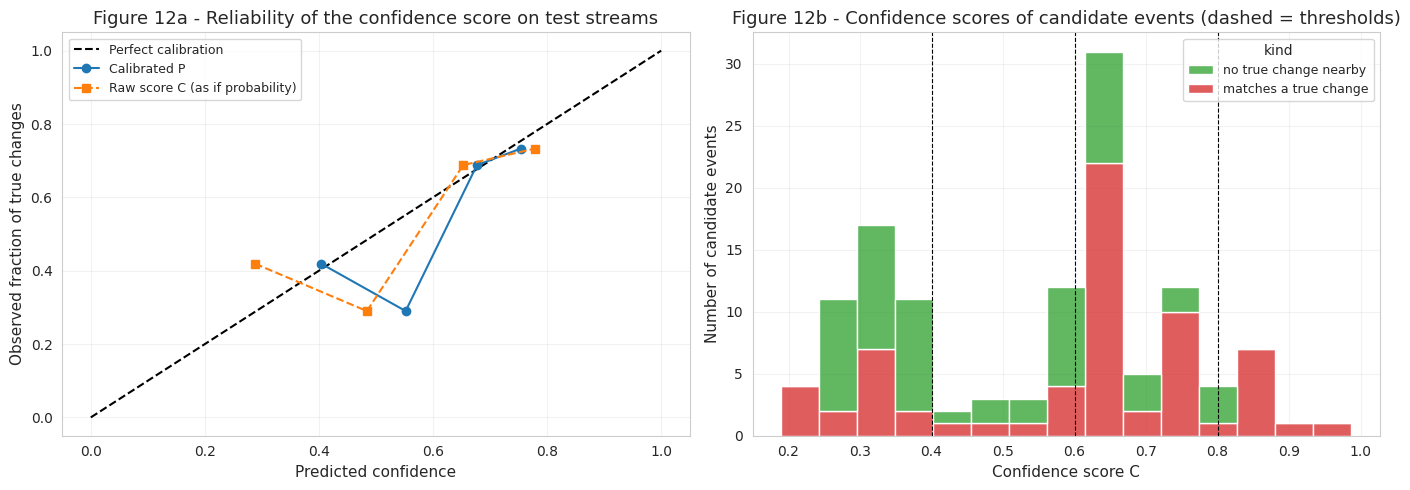

,Segment ID,Start Time,End Time,Duration,Pattern,Confidence,Calibrated P(change),Samples,Library cluster
0,1,2024-01-01 00:00:00,2024-01-01 04:54:00,0 days 04:55:00,Stable,initial,NaN,295,0
1,2,2024-01-01 04:55:00,2024-01-01 10:07:00,0 days 05:13:00,Noisy,0.65 (Medium),0.68,313,0
2,3,2024-01-01 10:08:00,2024-01-01 11:57:00,0 days 01:50:00,Decreasing Trend,0.66 (Medium),0.69,110,1
3,4,2024-01-01 11:58:00,2024-01-01 15:02:00,0 days 03:05:00,Decreasing Trend,0.67 (Medium),0.69,185,1
4,5,2024-01-01 15:03:00,2024-01-01 19:26:00,0 days 04:24:00,Stable,0.65 (Medium),0.67,264,3
5,6,2024-01-01 19:27:00,2024-01-02 02:14:00,0 days 06:48:00,Skewed Distribution,0.61 (Medium),0.65,408,3
6,7,2024-01-02 02:15:00,2024-01-02 02:44:00,0 days 00:30:00,Sudden Spike,0.67 (Medium),0.69,30,-1
7,8,2024-01-02 02:45:00,2024-01-02 07:51:00,0 days 05:07:00,Stable,0.83 (High),0.79,307,3
8,9,2024-01-02 07:52:00,2024-01-02 14:06:00,0 days 06:15:00,Periodic,0.67 (Medium),0.69,375,3
9,10,2024-01-02 14:07:00,2024-01-02 19:15:00,0 days 05:09:00,High-Level,0.75 (Medium),0.74,309,3


In [ ]:
PRE_TOL, POST_TOL = 15, 60

def match_detections(true_cps, declared):
    used, pairs = set(), []
    for k in np.argsort(declared):
        d = declared[k]; best, bd = None, 1e9
        for j, c in enumerate(true_cps):
            if j not in used and c - PRE_TOL <= d <= c + POST_TOL and abs(d - c) < bd: best, bd = j, abs(d - c)
        if best is not None: used.add(best); pairs.append((k, best))
    return pairs

def labels_from_boundaries(b, N):
    lab = np.zeros(N, int)
    for x in sorted(b): lab[int(x):] += 1
    return lab

def evaluate(S, res, elapsed):
    declared, bound = np.asarray(res["declared"], int), np.asarray(res["boundary"], int); pairs = match_detections(S.true_cps, declared)
    tp = len(pairs); fp = len(declared) - tp; fn = len(S.true_cps) - tp
    prec = tp / (tp + fp) if tp + fp else 0.0; rec = tp / (tp + fn) if tp + fn else 0.0; f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    delay = np.mean([max(0, declared[k] - S.true_cps[j]) for k, j in pairs]) if pairs else np.nan
    loc = np.mean([abs(bound[k] - S.true_cps[j]) for k, j in pairs]) if pairs else np.nan
    pl = labels_from_boundaries(bound, S.N)
    return dict(TP=tp, FP=fp, FN=fn, Precision=prec, Recall=rec, F1=f1, FAR_per_1000=1000 * fp / S.N, Delay=delay, LocError=loc, ARI=adjusted_rand_score(S.regs, pl),
                NMI=normalized_mutual_info_score(S.regs, pl), Boundaries=len(declared), Time_s=elapsed, us_per_sample=1e6 * elapsed / S.N)

def detect_fixed(N, W=200): b = list(range(W, N, W)); return dict(boundary=b, declared=b)

def detect_kmeans(x, ts, w=30, step=5, kmax=8, min_run=3):
    F = extract_features(x, ts, w, step); X = StandardScaler().fit_transform(F[CLUSTER_COLS].values); best = (-2, None)
    for k in range(2, kmax + 1):
        lab = KMeans(k, n_init=5, random_state=SEED).fit_predict(X); sc = silhouette_score(X, lab)
        if sc > best[0]: best = (sc, lab)
    lab = best[1].copy(); sm = lab.copy()
    for j in range(len(lab)): sm[j] = np.bincount(lab[max(0, j - 2):j + 3]).argmax()          # mode filter (5 windows)
    b, d, cur = [], [], sm[0]; j = 1
    while j < len(sm) - min_run + 1:
        if sm[j] != cur and (sm[j:j + min_run] == sm[j]).all(): b.append(int(F.end_idx[j] - w // 2)); d.append(int(F.end_idx[j + min_run - 1])); cur = sm[j]
        j += 1
    return dict(boundary=b, declared=d)

def seg_to_res(seg): return dict(boundary=seg.boundaries, declared=seg.declared)

def run_methods(S, cfg, include_ablation=True):
    out = {}
    def timed(name, fn):
        t0 = time.perf_counter(); r = fn(); out[name] = (r, time.perf_counter() - t0)
    timed("Fixed window (W=200)", lambda: detect_fixed(S.N))
    timed("K-Means based", lambda: detect_kmeans(S.x, S.ts))
    timed("ADWIN based", lambda: detect_adwin(S.x))
    timed("Sliding-window stat. test", lambda: detect_sliding_stats(S.x))
    seg, t = run_segmenter(S.x, cfg, S.sigma0); out["Proposed (confidence-aware)"] = (seg_to_res(seg), t); out["_seg"] = seg
    if include_ablation:
        seg2, t2 = run_segmenter(S.x, replace(cfg, use_confidence=False, use_library=False), S.sigma0); out["Ablation: alarm-only (no confidence gate)"] = (seg_to_res(seg2), t2)
    return out

rows = []
for tau in [0.50, 0.60, 0.70]:
    for sd in VAL_SEEDS:
        Sv = STREAMS[sd]; seg, t = run_segmenter(Sv.x, replace(CFG, tau_med=tau, use_library=False), Sv.sigma0); m = evaluate(Sv, seg_to_res(seg), t); rows.append(dict(tau_med=tau, stream=sd, **m))
VAL = pd.DataFrame(rows); val_tab = VAL.groupby("tau_med")[["Precision", "Recall", "F1", "FAR_per_1000", "Delay"]].mean().round(3); display(val_tab)
TAU_BEST = float(val_tab.F1.round(6).iloc[::-1].idxmax()); print(f"Selected tau_med = {TAU_BEST} (highest mean validation F1; ties -> larger threshold)")
CFG_FINAL = replace(CFG, tau_med=TAU_BEST)

def label_events(S, events, tol=40):
    cps = np.asarray(S.true_cps); return np.array([int(len(cps) > 0 and np.min(np.abs(cps - e["onset"])) <= tol) for e in events])
cal_s, cal_y = [], []
for tau in [TAU_BEST, 0.45]:
    for sd in VAL_SEEDS:
        Sv = STREAMS[sd]; seg, _ = run_segmenter(Sv.x, replace(CFG, tau_med=tau, use_library=False), Sv.sigma0); ev_ = [e for e in seg.events if e["status"] != "unresolved"]
        cal_s += [e["score"] for e in ev_]; cal_y += list(label_events(Sv, ev_))
cal_s, cal_y = np.array(cal_s), np.array(cal_y)
if len(set(cal_y)) == 2:
    PLATT = LogisticRegression(C=100.0).fit(cal_s[:, None], cal_y); CALIBRATE = lambda s: float(PLATT.predict_proba(np.array([[s]]))[0, 1])
    joblib.dump(PLATT, "confidence_calibrator.joblib"); print(f"Platt calibrator fitted on {len(cal_y)} validation candidate events ({cal_y.sum()} true / {len(cal_y)-cal_y.sum()} false) and saved with joblib.")
else:
    CALIBRATE = lambda s: float(np.clip(s, 0, 1)); print("Validation events had a single class: calibration skipped (identity map).")
display(pd.DataFrame({"score C": [0.3, 0.45, 0.6, 0.7, 0.8, 0.9, 1.0]}).assign(**{"calibrated P(true change)": lambda d: [round(CALIBRATE(s), 3) for s in d["score C"]]}))

ALL_ROWS, TEST_SEGS, TEST_EVENTS, TEST_OUT = [], {}, [], {}
for sd in TEST_SEEDS:
    St = STREAMS[sd]; out = run_methods(St, CFG_FINAL); TEST_SEGS[sd] = out.pop("_seg"); TEST_OUT[sd] = out
    for name, (res, el) in out.items():
        ALL_ROWS.append(dict(method=name, stream=sd, **evaluate(St, res, el)))
    ev_ = [e for e in TEST_SEGS[sd].events if e["status"] != "unresolved"]; lab = label_events(St, ev_)
    TEST_EVENTS += [dict(stream=sd, score=e["score"], status=e["status"], y=int(l)) for e, l in zip(ev_, lab)]
RES = pd.DataFrame(ALL_ROWS); METRICS = ["Precision", "Recall", "F1", "FAR_per_1000", "Delay", "LocError", "ARI", "NMI", "Boundaries", "Time_s", "us_per_sample"]
ORDER = ["Fixed window (W=200)", "K-Means based", "ADWIN based", "Sliding-window stat. test", "Ablation: alarm-only (no confidence gate)", "Proposed (confidence-aware)"]
SUMMARY = RES.groupby("method")[METRICS].agg(["mean", "std"]).reindex(ORDER)
print("Test streams:", TEST_SEEDS, "| true change points per stream:", [len(STREAMS[s].true_cps) for s in TEST_SEEDS])
display(RES.groupby("method")[METRICS].mean().reindex(ORDER).round(3))
display(RES[RES.method == "Proposed (confidence-aware)"].set_index("stream")[["TP", "FP", "FN", "Precision", "Recall", "F1", "FAR_per_1000", "Delay", "LocError", "ARI"]].round(3))
RES.to_csv("evaluation_results.csv", index=False)

TE = pd.DataFrame(TEST_EVENTS); TE["p_cal"] = [CALIBRATE(s) for s in TE.score]
print(f"Test candidate events: {len(TE)} ({TE.y.sum()} true, {(1-TE.y).sum()} false) | Brier score of calibrated P: {np.mean((TE.p_cal-TE.y)**2):.3f} | Brier of raw score: {np.mean((TE.score.clip(0,1)-TE.y)**2):.3f}")
bins = pd.qcut(TE.score, q=min(4, TE.score.nunique()), duplicates="drop"); REL = TE.groupby(bins).agg(events=("y", "size"), mean_score=("score", "mean"), mean_calibrated=("p_cal", "mean"), observed_true_rate=("y", "mean")).round(3)
display(REL); ECE = float((REL.events * (REL.mean_calibrated - REL.observed_true_rate).abs()).sum() / REL.events.sum()); print(f"Expected calibration error (calibrated P, {len(REL)} bins): {ECE:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot([0, 1], [0, 1], "k--", label="Perfect calibration"); ax[0].plot(REL.mean_calibrated, REL.observed_true_rate, "o-", label="Calibrated P"); ax[0].plot(REL.mean_score.clip(0, 1), REL.observed_true_rate, "s--", label="Raw score C (as if probability)")
ax[0].set_title("Figure 12a - Reliability of the confidence score on test streams"); ax[0].set_xlabel("Predicted confidence"); ax[0].set_ylabel("Observed fraction of true changes"); ax[0].legend()
sns.histplot(data=TE.assign(kind=np.where(TE.y == 1, "matches a true change", "no true change nearby")), x="score", hue="kind", bins=15, multiple="stack", ax=ax[1], palette=["tab:green", "tab:red"])
for thr in (CFG.tau_low, TAU_BEST, CFG.tau_high): ax[1].axvline(thr, ls="--", color="k", lw=0.8)
ax[1].set_title("Figure 12b - Confidence scores of candidate events (dashed = thresholds)"); ax[1].set_xlabel("Confidence score C"); ax[1].set_ylabel("Number of candidate events"); plt.tight_layout(); plt.show()

SEG_FINAL = TEST_SEGS[DEMO]; TABLE_FINAL = build_segment_table(S, SEG_FINAL, CALIBRATE)
display(TABLE_FINAL[["Segment ID", "Start Time", "End Time", "Duration", "Pattern", "Confidence", "Calibrated P(change)", "Samples", "Library cluster"]].round(2))
TABLE_FINAL.to_csv("segmentation_demo_stream.csv", index=False)

Comparison table: mean ± std over 5 test streams (Delay and LocError in samples = minutes; FAR = false alarms per 1000 samples)


,Precision,Recall,F1,FAR_per_1000,Delay,LocError,ARI,NMI,Boundaries,Time (s)
Fixed window (W=200),0.234 ± 0.038,0.327 ± 0.050,0.273 ± 0.043,3.71 ± 0.18,20.77 ± 11.83,23.27 ± 11.08,0.582 ± 0.019,0.792 ± 0.012,15.40 ± 0.55,0.000
K-Means based,0.778 ± 0.062,0.636 ± 0.129,0.695 ± 0.088,0.63 ± 0.23,22.79 ± 2.08,13.39 ± 1.45,0.581 ± 0.144,0.805 ± 0.060,9.00 ± 1.73,0.334
ADWIN based,0.402 ± 0.109,0.255 ± 0.076,0.311 ± 0.087,1.32 ± 0.35,25.08 ± 13.89,189.47 ± 80.80,0.463 ± 0.057,0.704 ± 0.025,7.00 ± 1.00,0.003
Sliding-window stat. test,0.419 ± 0.029,0.800 ± 0.076,0.549 ± 0.042,3.83 ± 0.11,21.32 ± 5.59,18.73 ± 2.96,0.684 ± 0.048,0.821 ± 0.016,21.00 ± 0.71,0.748
Ablation: alarm-only (no confidence gate),0.333 ± 0.049,0.945 ± 0.050,0.492 ± 0.059,6.64 ± 0.99,10.44 ± 2.65,6.44 ± 1.64,0.743 ± 0.062,0.857 ± 0.021,31.60 ± 3.36,2.301
Proposed (confidence-aware),0.653 ± 0.064,0.782 ± 0.104,0.710 ± 0.069,1.44 ± 0.35,12.00 ± 2.05,5.69 ± 5.23,0.812 ± 0.103,0.908 ± 0.037,13.20 ± 1.64,3.893


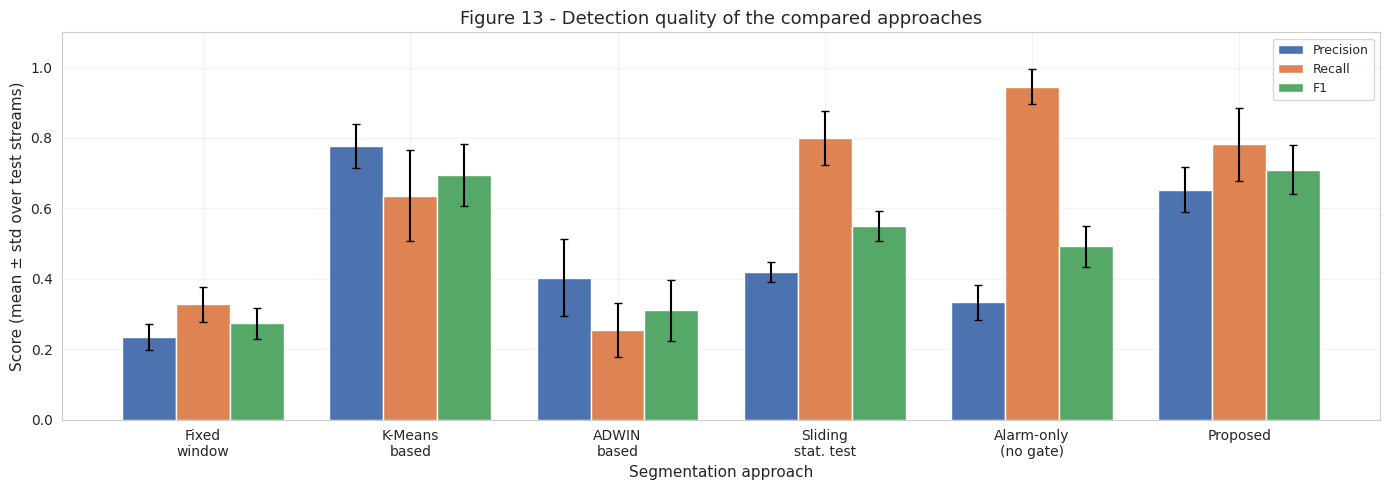

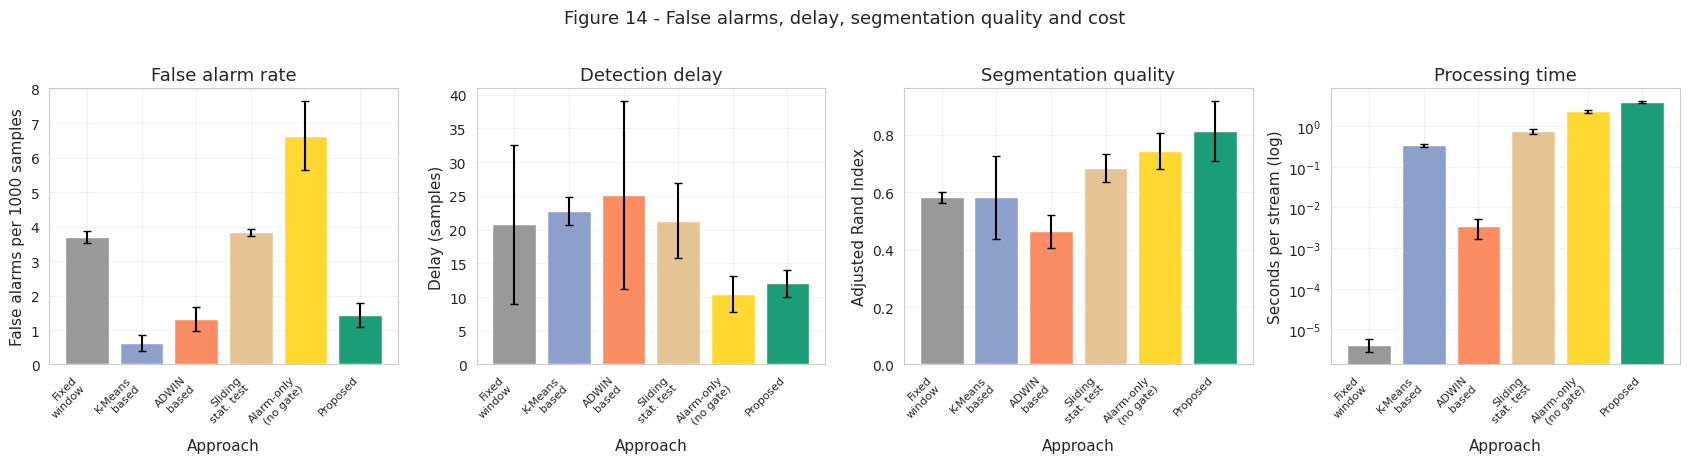

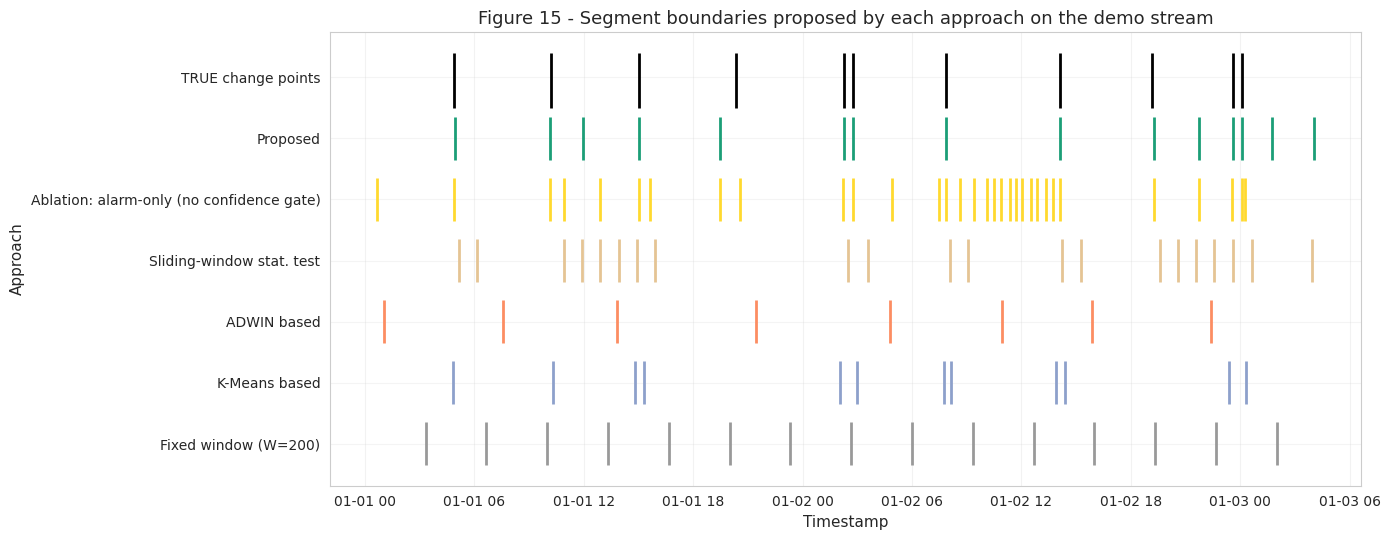

Pattern-name accuracy over 71 detected segments: 80.28% (sample-weighted 82.82%)


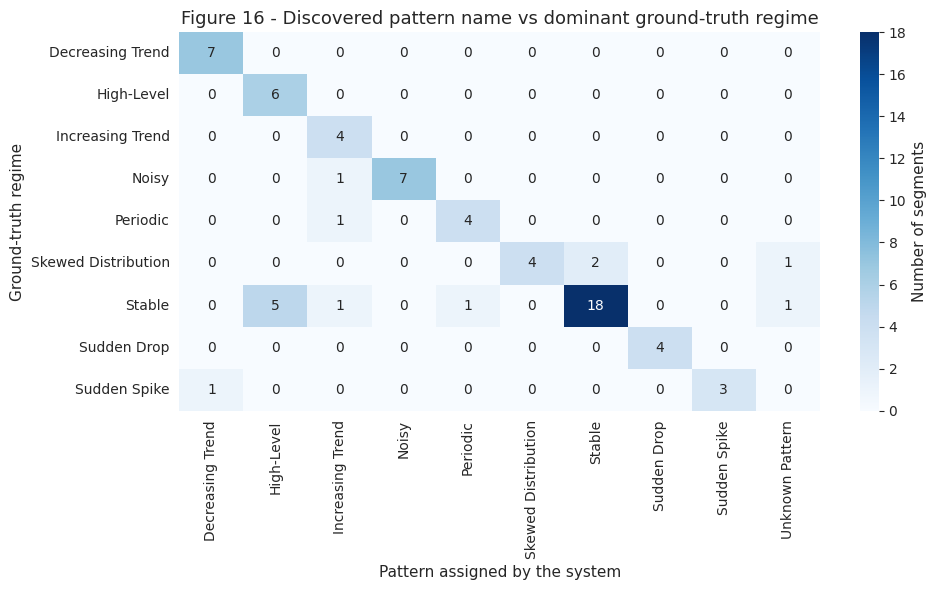

Recall of the proposed system by the type of regime that STARTS at the change point:


,recall,n
regime_entered,,
Decreasing Trend,1.0,5
High-Level,1.0,5
Increasing Trend,0.6,5
Noisy,0.8,5
Periodic,0.8,5
Skewed Distribution,0.0,5
Stable,0.8,15
Sudden Drop,1.0,5
Sudden Spike,1.0,5


In [ ]:
def fmt(m, s, d=3): return f"{m:.{d}f} ± {s:.{d}f}"
disp = pd.DataFrame({k: [fmt(SUMMARY.loc[n, (k, "mean")], SUMMARY.loc[n, (k, "std")], 2 if k in ("Delay", "LocError", "FAR_per_1000", "Boundaries") else 3) for n in ORDER]
                     for k in ["Precision", "Recall", "F1", "FAR_per_1000", "Delay", "LocError", "ARI", "NMI", "Boundaries"]}, index=ORDER)
disp["Time (s)"] = [f"{SUMMARY.loc[n, ('Time_s', 'mean')]:.3f}" for n in ORDER]
print("Comparison table: mean ± std over", len(TEST_SEEDS), "test streams (Delay and LocError in samples = minutes; FAR = false alarms per 1000 samples)")
display(disp); disp.to_csv("comparison_table.csv")

short = {n: n.replace("Ablation: alarm-only (no confidence gate)", "Alarm-only\n(no gate)").replace("Proposed (confidence-aware)", "Proposed").replace("Sliding-window stat. test", "Sliding\nstat. test").replace(" based", "\nbased").replace("Fixed window (W=200)", "Fixed\nwindow") for n in ORDER}
cols = {"Fixed window (W=200)": "#999999", "K-Means based": "#8da0cb", "ADWIN based": "#fc8d62", "Sliding-window stat. test": "#e5c494", "Ablation: alarm-only (no confidence gate)": "#ffd92f", "Proposed (confidence-aware)": "#1b9e77"}
fig, ax = plt.subplots(figsize=(14, 5)); wd = 0.26
for k, (m, off) in enumerate([("Precision", -wd), ("Recall", 0), ("F1", wd)]):
    ax.bar(np.arange(len(ORDER)) + off, [SUMMARY.loc[n, (m, "mean")] for n in ORDER], wd, yerr=[SUMMARY.loc[n, (m, "std")] for n in ORDER], capsize=3, label=m, color=["#4c72b0", "#dd8452", "#55a868"][k])
ax.set_xticks(range(len(ORDER))); ax.set_xticklabels([short[n] for n in ORDER]); ax.set_ylim(0, 1.1); ax.set_ylabel("Score (mean ± std over test streams)"); ax.set_xlabel("Segmentation approach")
ax.set_title("Figure 13 - Detection quality of the compared approaches"); ax.legend(); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, (m, ttl, yl) in zip(axes, [("FAR_per_1000", "False alarm rate", "False alarms per 1000 samples"), ("Delay", "Detection delay", "Delay (samples)"),
                                   ("ARI", "Segmentation quality", "Adjusted Rand Index"), ("Time_s", "Processing time", "Seconds per stream (log)")]):
    ax.bar(range(len(ORDER)), [SUMMARY.loc[n, (m, "mean")] for n in ORDER], yerr=[SUMMARY.loc[n, (m, "std")] for n in ORDER], capsize=3, color=[cols[n] for n in ORDER])
    ax.set_xticks(range(len(ORDER))); ax.set_xticklabels([short[n] for n in ORDER], rotation=45, ha="right", fontsize=8); ax.set_title(ttl); ax.set_ylabel(yl); ax.set_xlabel("Approach")
    if m == "Time_s": ax.set_yscale("log")
fig.suptitle("Figure 14 - False alarms, delay, segmentation quality and cost", y=1.02, fontsize=13); plt.tight_layout(); plt.show()

OUT = TEST_OUT[DEMO]; fig, ax = plt.subplots(figsize=(14, 5.5))
for r, n in enumerate(ORDER):
    res = OUT[n][0]; ax.vlines(S.ts[np.clip(res["boundary"], 0, S.N - 1)], r - 0.35, r + 0.35, color=cols[n], lw=2)
ax.vlines(S.ts[S.true_cps], len(ORDER) - 0.5, len(ORDER) + 0.4, color="k", lw=2)
ax.set_yticks(list(range(len(ORDER))) + [len(ORDER)]); ax.set_yticklabels([n.replace(" (confidence-aware)", "") for n in ORDER] + ["TRUE change points"]); ax.grid(axis="y", alpha=0.2)
ax.set_title("Figure 15 - Segment boundaries proposed by each approach on the demo stream"); ax.set_xlabel("Timestamp"); ax.set_ylabel("Approach"); plt.tight_layout(); plt.show()

pairs = []
for sd in TEST_SEEDS:
    St, sg = STREAMS[sd], TEST_SEGS[sd]; labels, st_, edges = label_segments(St.x, sg.boundaries)
    for j, lab in enumerate(labels):
        a, b = edges[j], edges[j + 1]
        if b - a < 10: continue
        tr = St.truth.label[np.bincount(St.regs[a:b]).argmax()]; pairs.append((tr, lab, b - a))
PL = pd.DataFrame(pairs, columns=["true", "pred", "n"]); acc = float((PL.true == PL.pred).mean()); wacc = float(((PL.true == PL.pred) * PL.n).sum() / PL.n.sum())
print(f"Pattern-name accuracy over {len(PL)} detected segments: {acc:.2%} (sample-weighted {wacc:.2%})")
ct = pd.crosstab(PL.true, PL.pred); fig, ax = plt.subplots(figsize=(10, 6)); sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax, cbar_kws={"label": "Number of segments"})
ax.set_title("Figure 16 - Discovered pattern name vs dominant ground-truth regime"); ax.set_xlabel("Pattern assigned by the system"); ax.set_ylabel("Ground-truth regime"); plt.tight_layout(); plt.show()

miss = []
for sd in TEST_SEEDS:
    St = STREAMS[sd]; pr = match_detections(St.true_cps, np.asarray(TEST_OUT[sd]["Proposed (confidence-aware)"][0]["declared"])); hit = {j for _, j in pr}
    for j, c in enumerate(St.true_cps): miss.append(dict(regime_entered=St.truth.label[j + 1], detected=j in hit))
MS = pd.DataFrame(miss).groupby("regime_entered").detected.agg(["mean", "count"]).rename(columns={"mean": "recall", "count": "n"}).round(2)
print("Recall of the proposed system by the type of regime that STARTS at the change point:"); display(MS)

In [ ]:
M = RES.groupby("method")[["Precision", "Recall", "F1", "FAR_per_1000", "Delay", "LocError", "ARI", "Time_s"]].mean(); P_ = M.loc["Proposed (confidence-aware)"]
base = ["Fixed window (W=200)", "K-Means based", "ADWIN based", "Sliding-window stat. test"]; abl = M.loc["Ablation: alarm-only (no confidence gate)"]
best_base_f1 = M.loc[base, "F1"].idxmax(); lowest_far_base = M.loc[base, "FAR_per_1000"].idxmin()
lines = [f"**Test streams:** {len(TEST_SEEDS)} unseen synthetic streams, {sum(len(STREAMS[s].true_cps) for s in TEST_SEEDS)} true change points in total; detector backend: {'River' if USE_RIVER else 'built-in fallback'}; selected tau_med = {TAU_BEST} (chosen on validation streams).", "",
         f"**Proposed system:** precision {P_.Precision:.2f}, recall {P_.Recall:.2f}, F1 {P_.F1:.2f}, {P_.FAR_per_1000:.2f} false alarms per 1000 samples, mean detection delay {P_.Delay:.1f} samples, boundary localisation error {P_.LocError:.1f} samples, ARI {P_.ARI:.2f}, {P_.Time_s:.1f}s per stream.",
         f"**Best baseline by F1:** {best_base_f1} (F1 {M.loc[best_base_f1,'F1']:.2f}); **lowest baseline false-alarm rate:** {lowest_far_base} ({M.loc[lowest_far_base,'FAR_per_1000']:.2f} per 1000).",
         f"**Effect of the confidence gate (ablation):** false alarms {abl.FAR_per_1000:.2f} -> {P_.FAR_per_1000:.2f} per 1000 samples, precision {abl.Precision:.2f} -> {P_.Precision:.2f}, recall {abl.Recall:.2f} -> {P_.Recall:.2f}, mean delay {abl.Delay:.1f} -> {P_.Delay:.1f} samples.", ""]
fewer = P_.FAR_per_1000 < M.loc[base, "FAR_per_1000"].min() and P_.FAR_per_1000 < abl.FAR_per_1000; better_f1 = P_.F1 > M.loc[base, "F1"].max()
lines.append("**Answer to the research question (for this experiment):** " + (
    "yes on false boundaries - the confidence-aware system produced the fewest false alarms of all approaches" if fewer else
    "only partly - it reduced false alarms relative to the ungated ablation" if P_.FAR_per_1000 < abl.FAR_per_1000 else "no - it did not reduce false alarms in this run") +
    (", and it also achieved the highest F1 of the compared approaches" if better_f1 else ", but it did not achieve the highest F1 of all approaches") +
    f". Detection delay is {'higher' if P_.Delay > abl.Delay else 'not higher'} than the ungated detector ({P_.Delay:.1f} vs {abl.Delay:.1f} samples), i.e. evidence is paid for with time; whether the delay is 'low' depends on the application's tolerance (matching allowed up to {POST_TOL} samples).")
lines += ["", f"**Calibration:** on the unseen test events the calibrated confidence has an expected calibration error of {ECE:.2f} (Brier {np.mean((TE.p_cal-TE.y)**2):.2f}); with ~{len(cal_y)} validation events it should be treated as a rough guide, not a precise probability.",
          f"**Pattern naming:** {acc:.0%} of detected segments received the same name as the dominant true regime.", "",
          "**Caveats:** synthetic ground truth, a small number of streams and one tolerance setting; see Section 19. Files written to the working directory: evaluation_results.csv, comparison_table.csv, segmentation_demo_stream.csv, confidence_calibrator.joblib."]
display(Markdown("\n\n".join(lines)))

**Test streams:** 5 unseen synthetic streams, 55 true change points in total; detector backend: River; selected tau_med = 0.6 (chosen on validation streams).



**Proposed system:** precision 0.65, recall 0.78, F1 0.71, 1.44 false alarms per 1000 samples, mean detection delay 12.0 samples, boundary localisation error 5.7 samples, ARI 0.81, 3.9s per stream.

**Best baseline by F1:** K-Means based (F1 0.70); **lowest baseline false-alarm rate:** K-Means based (0.63 per 1000).

**Effect of the confidence gate (ablation):** false alarms 6.64 -> 1.44 per 1000 samples, precision 0.33 -> 0.65, recall 0.95 -> 0.78, mean delay 10.4 -> 12.0 samples.



**Answer to the research question (for this experiment):** only partly - it reduced false alarms relative to the ungated ablation, and it also achieved the highest F1 of the compared approaches. Detection delay is higher than the ungated detector (12.0 vs 10.4 samples), i.e. evidence is paid for with time; whether the delay is 'low' depends on the application's tolerance (matching allowed up to 60 samples).



**Calibration:** on the unseen test events the calibrated confidence has an expected calibration error of 0.08 (Brier 0.23); with ~162 validation events it should be treated as a rough guide, not a precise probability.

**Pattern naming:** 80% of detected segments received the same name as the dominant true regime.



**Caveats:** synthetic ground truth, a small number of streams and one tolerance setting; see Section 19. Files written to the working directory: evaluation_results.csv, comparison_table.csv, segmentation_demo_stream.csv, confidence_calibrator.joblib.